# Analysis phase - quantitative analysis of terminal processes and how they affect train departure delays from Alnabru

## Data import and format verification

In [179]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

pd.set_option("mode.string_storage", "python")

df = pd.read_parquet(
    "../data/cleaned_data/combined_cleaned_terminal_dataset.parquet"
)


print("Rows:", len(df))
print("Columns:", len(df.columns))

display(df.head())

Rows: 5219
Columns: 35


,Merknad,Tognummer,Avgangsdato,Lastefrist,Ferdig opplastet,Frist lok,Lok ankommet,Planlagt klart fra terminal,Klart fra terminal,Planlagt avgangstid - terminal,...,train_id,train_date,cancelled,Planlagt avgangstid - OTR,Faktisk avgangstid - OTR,actual_arrival_time,estimated_arrival_time,just_passing_through,Forsinkelse - OTR,train_company
0,PRI-TOG,5731,2025-08-01,08:50:00,08:45:00,09:02:00,08:30:00,09:37:00,08:58:00,09:42:00,...,5731,2025-08-01,N,09:42:00,09:15:00,<NA>,<NA>,False,-27,CN
1,NaN,5507,2025-08-01,11:40:00,11:40:00,11:43:00,12:00:00,12:18:00,11:30:00,12:23:00,...,5507,2025-08-01,N,12:16:00,12:22:00,<NA>,<NA>,False,6,CN
2,PRI-TOG,41900,2025-08-01,19:35:00,19:30:00,19:46:00,20:00:00,20:21:00,20:00:00,20:26:00,...,<NA>,NaT,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>
3,NaN,5709,2025-08-01,20:20:00,20:20:00,20:32:00,20:10:00,21:07:00,20:30:00,21:12:00,...,5709,2025-08-01,N,21:12:00,21:04:00,<NA>,<NA>,False,-8,CN
4,LANGTOG,5515,2025-08-01,21:15:00,21:15:00,21:17:00,20:57:00,21:52:00,21:15:00,21:57:00,...,5515,2025-08-01,N,21:57:00,21:42:00,<NA>,<NA>,False,-15,CN


In [180]:
# Data type for every column
display(df.dtypes.to_frame("Data type"))

# More detailed structural overview
df.info()

,Data type
Merknad,str
Tognummer,string
Avgangsdato,datetime64[us]
Lastefrist,string
Ferdig opplastet,string
Frist lok,string
Lok ankommet,string
Planlagt klart fra terminal,string
Klart fra terminal,string
Planlagt avgangstid - terminal,string


<class 'pandas.DataFrame'>
RangeIndex: 5219 entries, 0 to 5218
Data columns (total 35 columns):
 #   Column                            Non-Null Count  Dtype         
---  ------                            --------------  -----         
 0   Merknad                           2189 non-null   str           
 1   Tognummer                         5219 non-null   string        
 2   Avgangsdato                       5219 non-null   datetime64[us]
 3   Lastefrist                        5153 non-null   string        
 4   Ferdig opplastet                  4640 non-null   string        
 5   Frist lok                         5214 non-null   string        
 6   Lok ankommet                      4560 non-null   string        
 7   Planlagt klart fra terminal       5213 non-null   string        
 8   Klart fra terminal                4620 non-null   string        
 9   Planlagt avgangstid - terminal    5212 non-null   string        
 10  Faktisk avgangstid - terminal     4797 non-null   string   

### Preparation of dataset

*Note:* This analysis will not handle possible overnight departures, regardless if they were planned or not. Such departures will be excluded from the analysis, but the limitation is actknowledged.

In [181]:
# Create a clean code-only column as well: keeps only "Txx" from values like "T29 - Andre vinterproblemer"
df["Årsakskode - terminal (kode)"] = (
    df["Årsakskode - terminal"]
    .astype("string")
    .str.strip()
    .str.extract(r"^(T\d+)", expand=False)
    .str.upper()
)

In [182]:
# --------------------------------------------------
# Identify overnight departures and keep them in a separate dataframe
# --------------------------------------------------
df_overnight_departures = (
    df.loc[
        (
            df["Lastefrist"].notna()
            & df["Planlagt avgangstid - terminal"].notna()
            & df["Faktisk avgangstid - terminal"].notna()
            & (
                pd.to_timedelta(df["Lastefrist"], errors="coerce")
                > pd.to_timedelta(df["Planlagt avgangstid - terminal"], errors="coerce")
            )
            & (
                pd.to_timedelta(df["Lastefrist"], errors="coerce")
                > pd.to_timedelta(df["Faktisk avgangstid - terminal"], errors="coerce")
            )
        )
    ]
    .copy()
    .reset_index(drop=True)
)

print("Overnight departures found:", len(df_overnight_departures))
df_overnight_departures[
    [
        "LoggTogID",
        "Avgangsdato",
        "Tognummer",
        "Lastefrist",
        "Planlagt avgangstid - terminal",
        "Faktisk avgangstid - terminal",
    ]
].head()

Overnight departures found: 292


,LoggTogID,Avgangsdato,Tognummer,Lastefrist,Planlagt avgangstid - terminal,Faktisk avgangstid - terminal
0,03-08-2025_5711,2025-08-03,5711,12:00:00,08:12:00,07:19:00
1,18-08-2025_5301,2025-08-18,5301,19:30:00,08:51:00,07:51:00
2,01-09-2025_5301,2025-09-01,5301,19:30:00,08:51:00,09:20:00
3,08-09-2025_5301,2025-09-08,5301,19:30:00,08:51:00,08:49:00
4,15-09-2025_5301,2025-09-15,5301,19:30:00,08:51:00,08:58:00


In [183]:
# --------------------------------------------------
# Discard overnight records from the main dataframe
# --------------------------------------------------
overnight_logg_ids = df_overnight_departures["LoggTogID"].dropna().unique()

mask = ~df["LoggTogID"].isin(overnight_logg_ids)

df = df.loc[mask].copy().reset_index(drop=True)

print("Rows left after removal:", len(df))

Rows left after removal: 4927


## Actual analysis

*Note:* In the define phase, there was made a discovery that the winter operations vary a lot compared to the summer season. Because of that, there will first be done an analysis for the whole year, then the summer season (mar-nov), and then the winter season (dec-feb)

### Årsakskode-mapping
To have as a visual reference throughout

In [184]:
df_aarsakskodeliste = pd.read_csv("../data/Årsakskodelister (IKKE REDIGER!.csv", sep=";", encoding="utf-8-sig")

df_aarsakskodeliste

,Kode,Kort beskrivelse,Nedtrekks-tekst,Tilhørende YtelsesordningKode
0,T1,I rute,T1 - I rute,NaN
1,T2,Nytt tognummer (Skriv det nye i kommentar),T2 - Nytt tognummer (Skriv det nye i kommentar),Kode 7 - Trafikkavvikling (Infrastrukturs andel)
2,T3,Lokfører,T3 - Lokfører,Kode 83 - Manglende personell
3,T4,Forsinket ankommet tog. (kort snutid),T4 - Forsinket ankommet tog. (kort snutid),Kode 82 - Kjøretøy sent fra hensettingsspor
4,T5,Vognmangel,T5 - Vognmangel,Kode 85 - Planforutsetninger ikke oppfylt
5,T6,De-icing,T6 - De-icing,Kode 85 - Planforutsetninger ikke oppfylt
6,T7,Graving av snø,T7 - Graving av snø,Kode 92 - Ytre forhold
7,T8,Maskinmangel skifting,T8 - Maskinmangel skifting,Kode 84 - Stasjonsopphold
8,T9,Feil på vogn,T9 - Feil på vogn,Kode 81 - Feil ved kjøretøy
9,T10,Overbooking,T10 - Overbooking,Kode 85 - Planforutsetninger ikke oppfylt


### Whole year analysis

#### Baseline KPIs
- Total number of departures
- Number and percentage of delayed departures
- Mean delay
- Median delay
- 75th, 90th, and 95th percentile delay
- Maximum delay
- Total delay minutes
- Percentage of delays above relevant thresholds, for example:
    - At least 4 minutes
    - At least 10 minutes
    - At least 30 minutes

In [185]:
# Baseline KPI calculations

delay_col = "Forsinkelse - terminal"


delay = pd.to_numeric(
    df[delay_col],
    errors="coerce"
)

delay_non_negative = delay[
    delay >= 0
].dropna()

delay_stats = delay_non_negative.describe(
    percentiles=[0.50, 0.75, 0.90, 0.95]
)

def calculate_baseline_kpis(
    data,
    delay_col="Forsinkelse - terminal"
):
    """
    Calculate baseline KPIs for registered terminal delays.

    Negative delays, representing earlier departures, are excluded.
    Missing delay values are excluded.
    Zero-minute delays are retained.
    """

    # Convert delay values to numeric
    delay = pd.to_numeric(
        data[delay_col],
        errors="coerce"
    )

    # Keep only valid, non-negative delays
    delay_non_negative = delay[
        delay >= 0
    ].dropna()

    # Handle a group with no valid delay observations
    if delay_non_negative.empty:
        return pd.Series({
            "Antall rader i datasettet": len(data),
            "Antall med registrert terminalforsinkelse": delay.notna().sum(),
            "Antall gyldige, ikke-negative forsinkelser": 0,
            "Gjennomsnittlig forsinkelse (minutter)": pd.NA,
            "Medianforsinkelse (minutter)": pd.NA,
            "75-persentil (minutter)": pd.NA,
            "90-persentil (minutter)": pd.NA,
            "95-persentil (minutter)": pd.NA,
            "Maksimal forsinkelse (minutter)": pd.NA,
            "Andel av registrerte forsinkelser på minst 4 minutter (%)": pd.NA,
            "Andel av registrerte forsinkelser på minst 10 minutter (%)": pd.NA,
            "Andel av registrerte forsinkelser på minst 30 minutter (%)": pd.NA,
            "Totalt antall forsinkelsesminutter": 0,
        })

    # Pandas descriptive statistics
    delay_stats = delay_non_negative.describe(
        percentiles=[0.50, 0.75, 0.90, 0.95]
    )

    # Return the KPI values
    return pd.Series({
        # Counts and denominator information
        "Antall rader i datasettet": len(data),
        "Antall med registrert terminalforsinkelse": delay.notna().sum(),
        "Antall gyldige, ikke-negative forsinkelser":
            delay_non_negative.count(),

        # Descriptive statistics
        "Gjennomsnittlig forsinkelse (minutter)":
            delay_stats["mean"],
        "Medianforsinkelse (minutter)":
            delay_stats["50%"],
        "75-persentil (minutter)":
            delay_stats["75%"],
        "90-persentil (minutter)":
            delay_stats["90%"],
        "95-persentil (minutter)":
            delay_stats["95%"],
        "Maksimal forsinkelse (minutter)":
            delay_stats["max"],

        # Threshold percentages
        "Andel av registrerte forsinkelser på minst 4 minutter (%)":
            (delay_non_negative >= 4).mean() * 100,
        "Andel av registrerte forsinkelser på minst 10 minutter (%)":
            (delay_non_negative >= 10).mean() * 100,
        "Andel av registrerte forsinkelser på minst 30 minutter (%)":
            (delay_non_negative >= 30).mean() * 100,

        # Total delay burden
        "Totalt antall forsinkelsesminutter":
            delay_non_negative.sum(),
    })


# Calculate the whole-year baseline KPIs
baseline_kpi = calculate_baseline_kpis(df)

# Format as a table
baseline_kpi = baseline_kpi.round(2).to_frame(
    name="Verdi"
)

display(baseline_kpi)

,Verdi
Antall rader i datasettet,4927.00
Antall med registrert terminalforsinkelse,4501.00
"Antall gyldige, ikke-negative forsinkelser",1655.00
Gjennomsnittlig forsinkelse (minutter),20.56
Medianforsinkelse (minutter),7.00
75-persentil (minutter),25.00
90-persentil (minutter),53.00
95-persentil (minutter),76.00
Maksimal forsinkelse (minutter),450.00
Andel av registrerte forsinkelser på minst 4 minutter (%),61.57


#### Pareto diagrams of årsakskoder

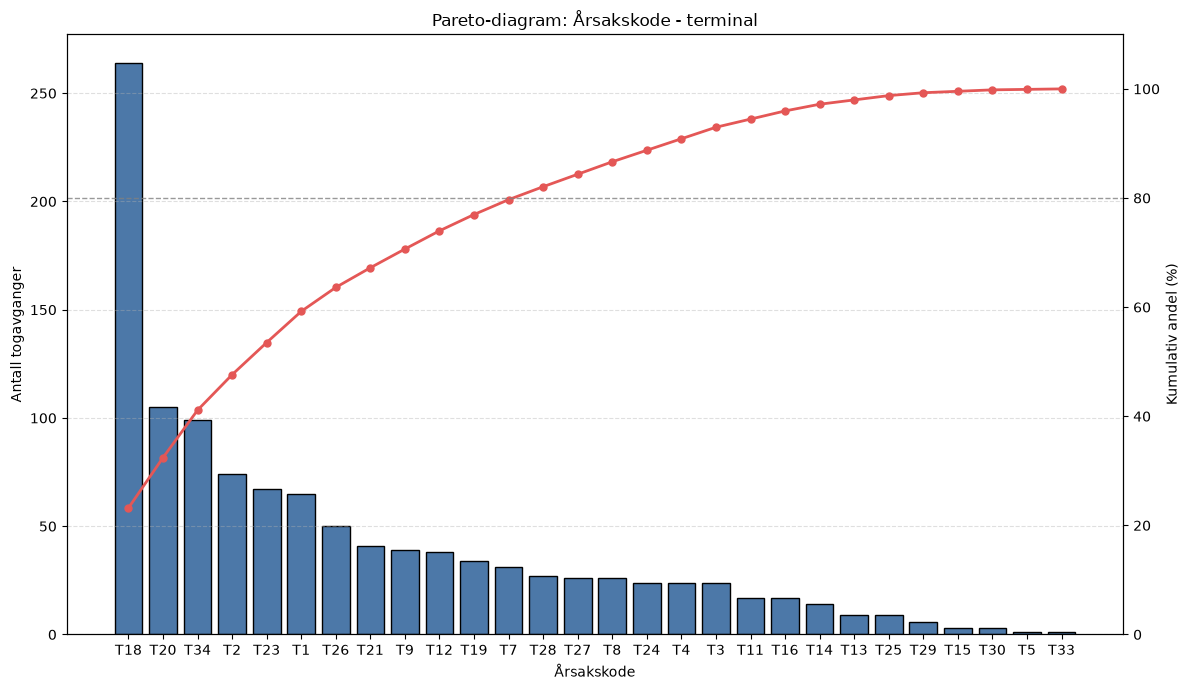

Total rows with a code: 1138

Top coded causes:
Årsakskode - terminal (kode)
T18    23.20
T20     9.23
T34     8.70
T2      6.50
T23     5.89
T1      5.71
T26     4.39
T21     3.60
T9      3.43
T12     3.34
T19     2.99
T7      2.72
T28     2.37
T27     2.28
T8      2.28
T24     2.11
T4      2.11
T3      2.11
T11     1.49
T16     1.49
T14     1.23
T13     0.79
T25     0.79
T29     0.53
T15     0.26
T30     0.26
T5      0.09
T33     0.09


In [186]:
# Use the new code column for the Pareto analysis
code_col = "Årsakskode - terminal (kode)"

# Keep only rows with a code
codes = df[code_col].dropna().astype(str).str.strip()
codes = codes[codes != ""]

# Count occurrences
code_counts = codes.value_counts().sort_values(ascending=False)

# Total number of coded rows
total_with_code = code_counts.sum()

# Proportion and cumulative share
share_pct = (code_counts / total_with_code) * 100
cum_pct = share_pct.cumsum()

# Optional: limit to top custom codes to avoid clutter
code_counts = code_counts.head(40)
share_pct = share_pct.loc[code_counts.index]
cum_pct = cum_pct.loc[code_counts.index]

# Plot
fig, ax1 = plt.subplots(figsize=(12, 7))

bars = ax1.bar(
    code_counts.index,
    code_counts.values,
    color="#4C78A8",
    edgecolor="black"
)

ax1.set_title("Pareto-diagram: Årsakskode - terminal")
ax1.set_xlabel("Årsakskode")
ax1.set_ylabel("Antall togavganger")
ax1.grid(axis="y", linestyle="--", alpha=0.4)

# Cumulative percentage on secondary axis
ax2 = ax1.twinx()
ax2.plot(
    code_counts.index,
    cum_pct.values,
    color="#E45756",
    marker="o",
    linewidth=2,
    markersize=5,
    label="Kumulativ %"
)
ax2.set_ylabel("Kumulativ andel (%)")
ax2.set_ylim(0, 110)

# Optional: 80% line
ax2.axhline(80, linestyle="--", color="gray", linewidth=1, alpha=0.8)

# Keep x-labels readable
ax1.tick_params(axis="x", rotation=0)
ax1.set_xticks(range(len(code_counts.index)))
ax1.set_xticklabels(code_counts.index)

plt.tight_layout()
plt.show()

print(f"Total rows with a code: {total_with_code}")
print("\nTop coded causes:")
print(share_pct.round(2).to_string())

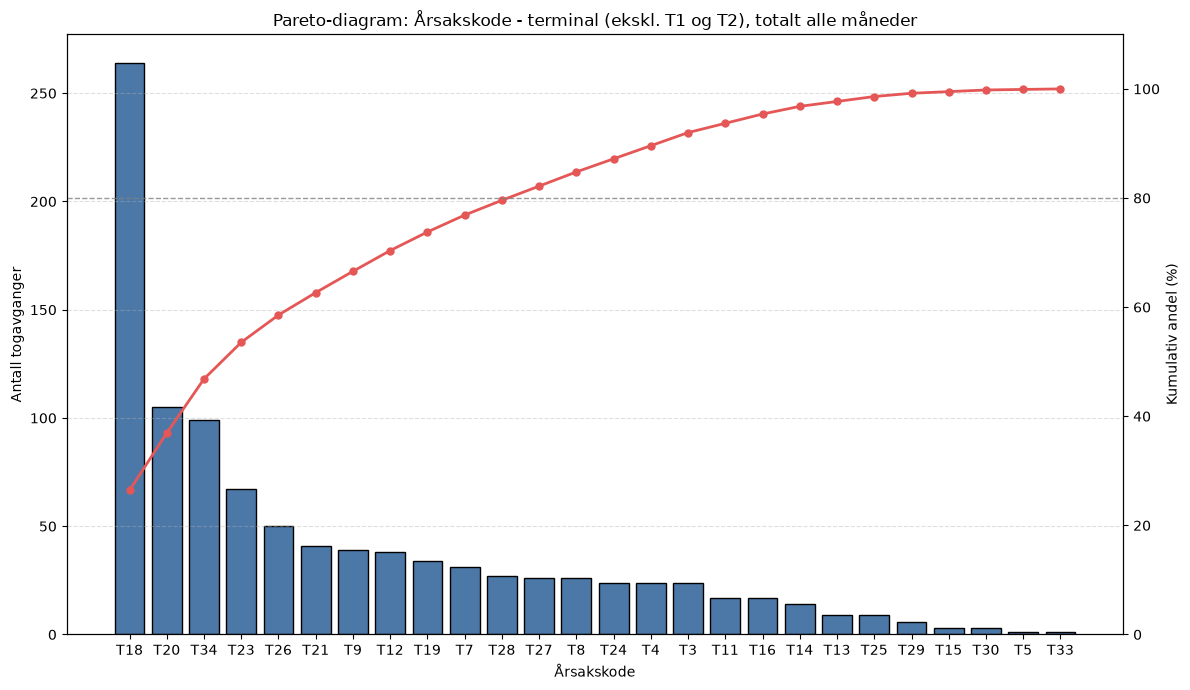

Total rows with a code after excluding T1 and T2: 999

Top codes after exclusion:
                              Andel (%)  Kumulativ andel (%)
Årsakskode - terminal (kode)                                
T18                               26.43                26.43
T20                               10.51                36.94
T34                                9.91                46.85
T23                                6.71                53.55
T26                                5.01                58.56
T21                                 4.1                62.66
T9                                  3.9                66.57
T12                                 3.8                70.37
T19                                 3.4                73.77
T7                                  3.1                76.88
T28                                 2.7                79.58
T27                                 2.6                82.18
T8                                  2.6                84.78
T24

In [187]:
# 2) Exclude T1 and T2 before analysis
excluded_codes = {"T1", "T2"}

df_aarsakskodeliste = df[
    df["Årsakskode - terminal (kode)"].notna() &
    ~df["Årsakskode - terminal (kode)"].isin(excluded_codes)
].copy()

# 3) Count only remaining codes
code_counts = (
    df_aarsakskodeliste["Årsakskode - terminal (kode)"]
    .value_counts()
    .sort_values(ascending=False)
)

# Optional: limit to the top N to reduce clutter
code_counts = code_counts.head(35)

# 4) Calculate total rows with valid codes after exclusion
total_with_code = code_counts.sum()

# 5) Calculate share and cumulative share
share_pct = (code_counts / total_with_code) * 100
cum_pct = share_pct.cumsum()

# 6) Plot Pareto chart
fig, ax1 = plt.subplots(figsize=(12, 7))

ax1.bar(code_counts.index, code_counts.values, color="#4C78A8", edgecolor="black")
ax1.set_title("Pareto-diagram: Årsakskode - terminal (ekskl. T1 og T2), totalt alle måneder")
ax1.set_xlabel("Årsakskode")
ax1.set_ylabel("Antall togavganger")
ax1.grid(axis="y", linestyle="--", alpha=0.4)

ax2 = ax1.twinx()
ax2.plot(code_counts.index, cum_pct.values, color="#E45756", marker="o",
         linewidth=2, markersize=5, label="Kumulativ %")
ax2.set_ylabel("Kumulativ andel (%)")
ax2.set_ylim(0, 110)

ax2.axhline(80, linestyle="--", color="gray", linewidth=1, alpha=0.8)

plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

print(f"Total rows with a code after excluding T1 and T2: {total_with_code}")
print("\nTop codes after exclusion:")
# print(share_pct.round(2).to_string())


print(
    pd.DataFrame({
        "Andel (%)": share_pct.round(2),
        "Kumulativ andel (%)": cum_pct.round(2)
    }).to_string())

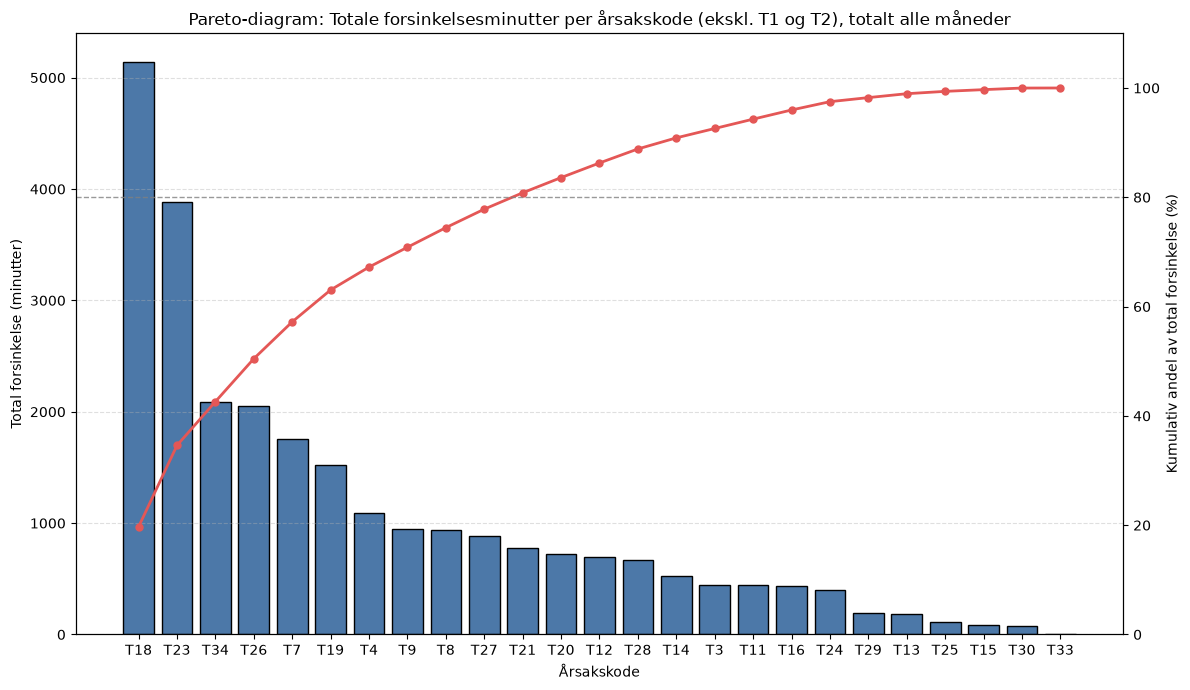

Total positiv forsinkelse: 26,078.0 minutter

Total forsinkelse per årsakskode:
                              Total forsinkelse (min)  Andel (%)  Kumulativ andel (%)
Årsakskode - terminal (kode)                                                         
T18                                              5141      19.71                19.71
T23                                              3883      14.89                 34.6
T34                                              2088       8.01                42.61
T26                                              2050       7.86                50.47
T7                                               1758       6.74                57.21
T19                                              1522       5.84                63.05
T4                                               1092       4.19                67.24
T9                                                945       3.62                70.86
T8                                                935       

In [188]:
code_col = "Årsakskode - terminal (kode)"
delay_col = "Forsinkelse - terminal"

# Create a working copy
df_forsinkelse = df_aarsakskodeliste.copy()

# Ensure the delay column is numeric
df_forsinkelse[delay_col] = pd.to_numeric(
    df_forsinkelse[delay_col],
    errors="coerce"
)

# Keep only rows with a valid code and non-negative delay
df_forsinkelse = df_forsinkelse[
    df_forsinkelse[code_col].notna()
    & df_forsinkelse[delay_col].notna()
    & (df_forsinkelse[delay_col] >= 0)
].copy()

# Aggregate total delay per cause code
delay_by_code = (
    df_forsinkelse
    .groupby(code_col)[delay_col]
    .sum()
    .sort_values(ascending=False)
)

# Total positive delay across all included codes
total_delay = delay_by_code.sum()

# Percentage and cumulative percentage
share_pct = (delay_by_code / total_delay) * 100
cum_pct = share_pct.cumsum()

# Pareto diagram
fig, ax1 = plt.subplots(figsize=(12, 7))

ax1.bar(
    delay_by_code.index,
    delay_by_code.values,
    color="#4C78A8",
    edgecolor="black"
)

ax1.set_title(
    "Pareto-diagram: Totale forsinkelsesminutter per årsakskode (ekskl. T1 og T2), totalt alle måneder"
)
ax1.set_xlabel("Årsakskode")
ax1.set_ylabel("Total forsinkelse (minutter)")
ax1.grid(axis="y", linestyle="--", alpha=0.4)

# Cumulative percentage line
ax2 = ax1.twinx()
ax2.plot(
    delay_by_code.index,
    cum_pct.values,
    color="#E45756",
    marker="o",
    linewidth=2,
    markersize=5
)

ax2.set_ylabel("Kumulativ andel av total forsinkelse (%)")
ax2.set_ylim(0, 110)
ax2.axhline(
    80,
    color="gray",
    linestyle="--",
    linewidth=1,
    alpha=0.8
)

ax1.tick_params(axis="x", rotation=0)

plt.tight_layout()
plt.show()

print(f"Total positiv forsinkelse: {total_delay:,.1f} minutter")
print("\nTotal forsinkelse per årsakskode:")
print(
    pd.DataFrame({
        "Total forsinkelse (min)": delay_by_code.round(1),
        "Andel (%)": share_pct.round(2),
        "Kumulativ andel (%)": cum_pct.round(2)
    }).to_string()
)

#### Distribution of delay duration
(+ Delay distribution with a reason code vs Delay distribution without a reason code)

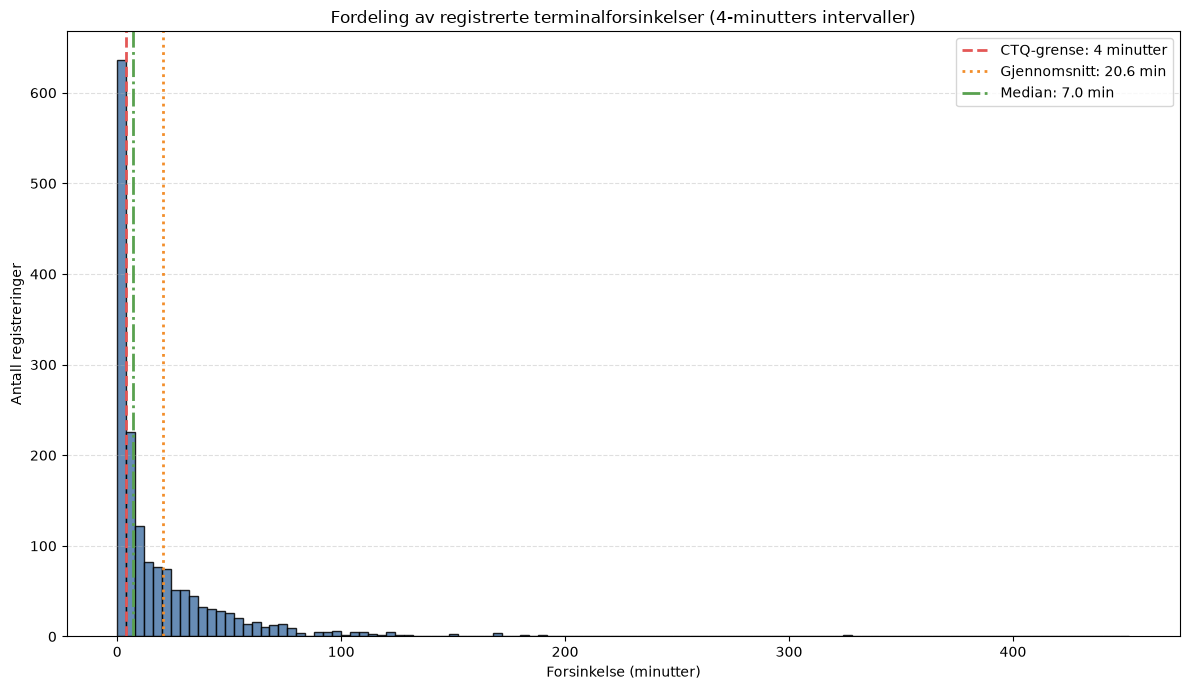

In [189]:
# Distribution of registered delays

bin_width = 4

max_delay = delay_non_negative.max()

bin_edges = range(
    0,
    int(max_delay) + bin_width + 1,
    bin_width
)

fig, ax = plt.subplots(figsize=(12, 7))

ax.hist(
    delay_non_negative,
    bins=bin_edges,
    color="#4C78A8",
    edgecolor="black",
    alpha=0.85
)

# CTQ limit
ax.axvline(
    4,
    color="#E45756",
    linestyle="--",
    linewidth=2,
    label="CTQ-grense: 4 minutter"
)

# Reuse statistics calculated in cell 16
ax.axvline(
    delay_stats["mean"],
    color="#F28E2B",
    linestyle=":",
    linewidth=2,
    label=f"Gjennomsnitt: {delay_stats['mean']:.1f} min"
)

ax.axvline(
    delay_stats["50%"],
    color="#59A14F",
    linestyle="-.",
    linewidth=2,
    label=f"Median: {delay_stats['50%']:.1f} min"
)

ax.set_title(
    "Fordeling av registrerte terminalforsinkelser "
    "(4-minutters intervaller)"
)
ax.set_xlabel("Forsinkelse (minutter)")
ax.set_ylabel("Antall registreringer")

ax.grid(
    axis="y",
    linestyle="--",
    alpha=0.4
)

ax.legend()

plt.tight_layout()
plt.show()

*Comment:* Some clear outliers here make the histogram compressed near zero, let's try to limit the visual x-axis for a more detailed view:

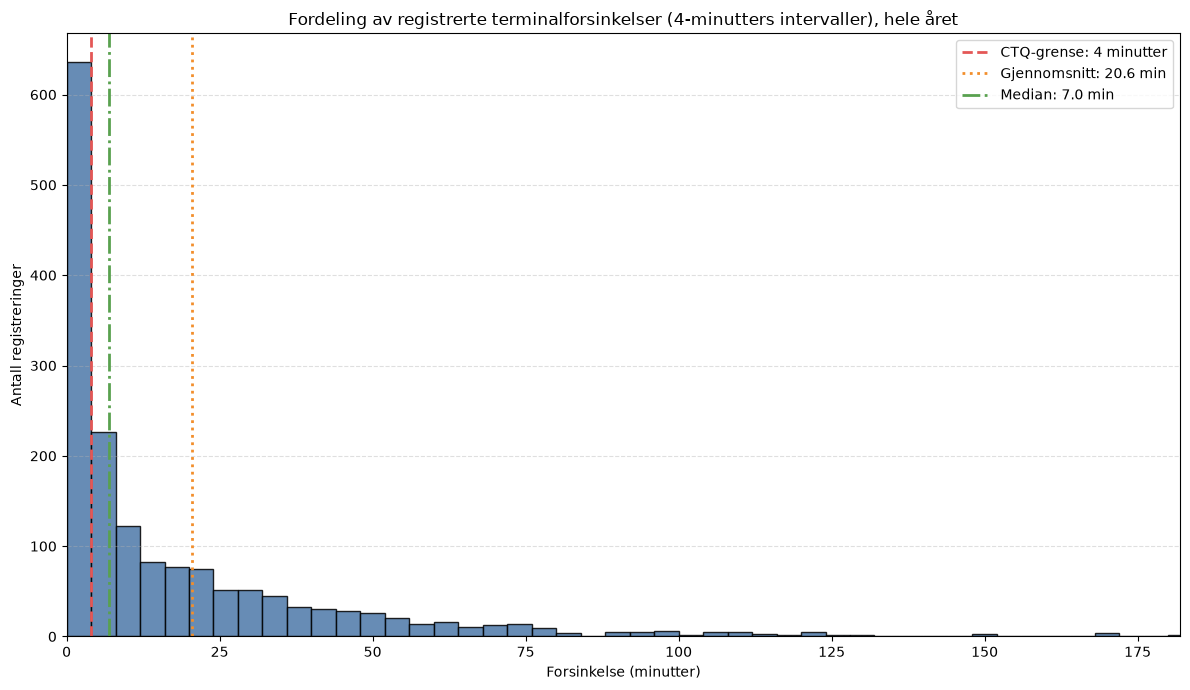

In [190]:
# Fordeling av registrerte forsinkelser med 4-minutters intervaller

bin_width = 4

# Create bin edges up to and beyond the maximum delay
max_delay = delay_non_negative.max()
bin_edges = range(
    0,
    int(max_delay) + bin_width + 1,
    bin_width
)

fig, ax = plt.subplots(figsize=(12, 7))

ax.hist(
    delay_non_negative,
    bins=bin_edges,
    color="#4C78A8",
    edgecolor="black",
    alpha=0.85
)

# CTQ limit
ax.axvline(
    4,
    color="#E45756",
    linestyle="--",
    linewidth=2,
    label="CTQ-grense: 4 minutter"
)

# Reuse statistics calculated in the KPI cell
ax.axvline(
    delay_stats["mean"],
    color="#F28E2B",
    linestyle=":",
    linewidth=2,
    label=f"Gjennomsnitt: {delay_stats['mean']:.1f} min"
)

ax.axvline(
    delay_stats["50%"],
    color="#59A14F",
    linestyle="-.",
    linewidth=2,
    label=f"Median: {delay_stats['50%']:.1f} min"
)

ax.set_title(
    "Fordeling av registrerte terminalforsinkelser (4-minutters intervaller), hele året"
)
ax.set_xlabel("Forsinkelse (minutter)")
ax.set_ylabel("Antall registreringer")

ax.grid(
    axis="y",
    linestyle="--",
    alpha=0.4
)

ax.legend()
ax.set_xlim(0, delay_non_negative.quantile(0.99)) # Limit the visual view to the 99th percentile

plt.tight_layout()
plt.show()

*Comment:* Most departures are cleary within the 4-minute-CTQ. The distribution also have a long, right tail.

#### Whole-year overview

*Note:* September 2026 is excluded from the monthly comparison because the dataset only covers the period from 1 August 2025 to 16 September 2026. Results for September are based on a partial month and are therefore reported separately.

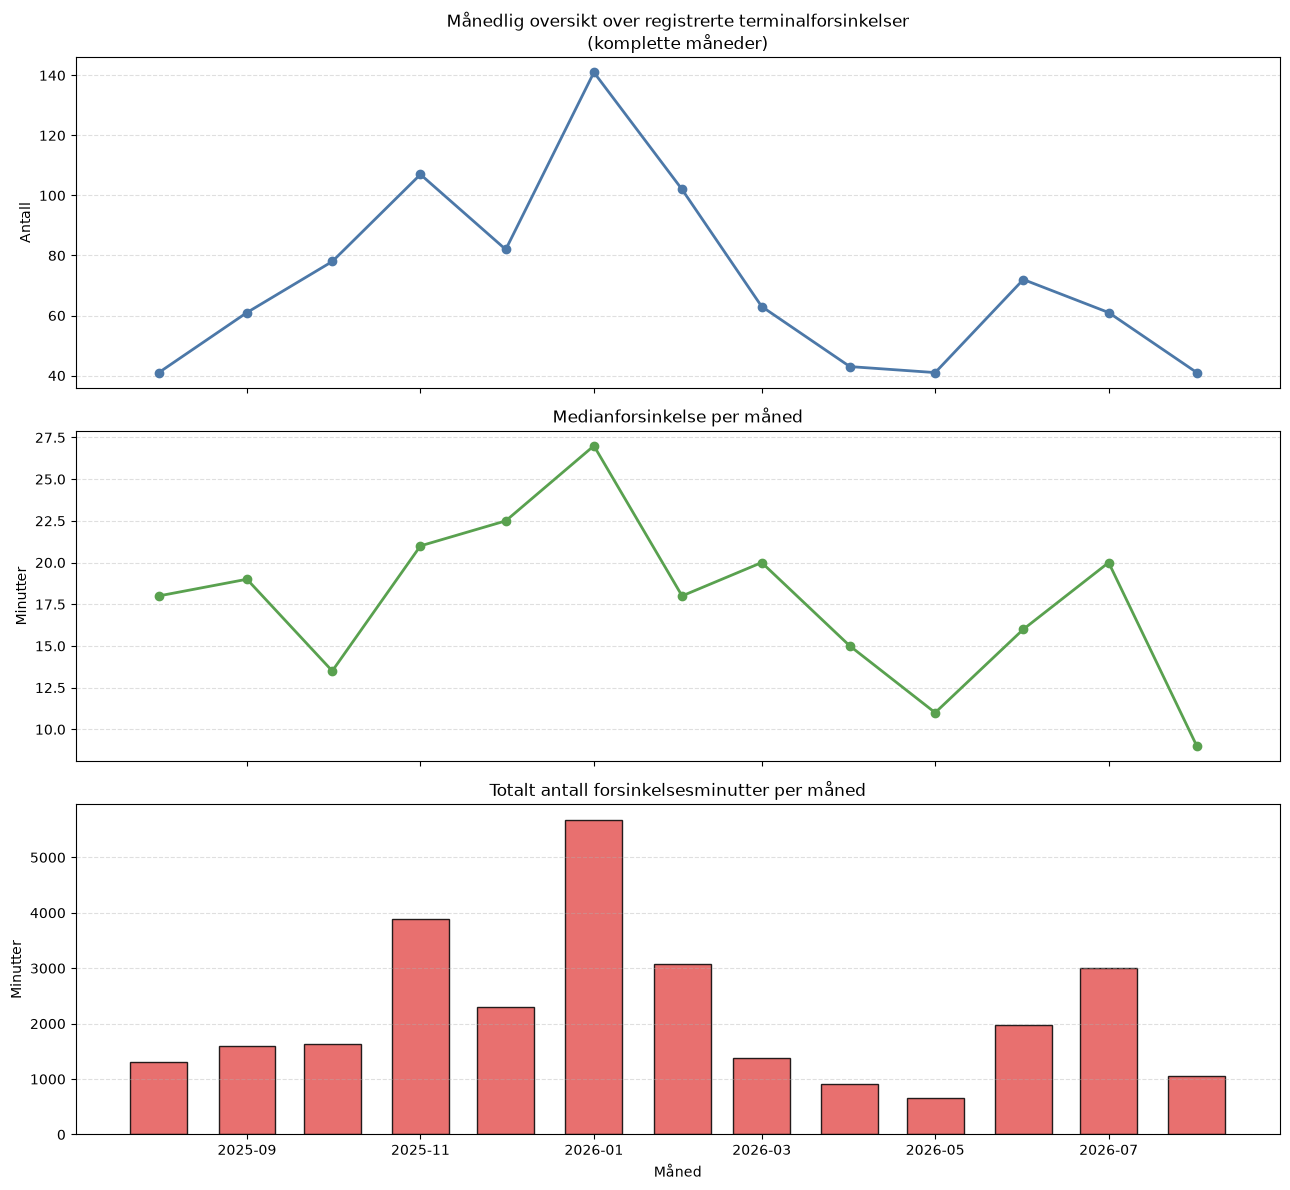

In [191]:
# Whole-year monthly overview

delay_col = "Forsinkelse - terminal"
date_col = "Dato"

# Reuse delay_non_negative from the KPI cell.
# It already contains only valid, non-negative delays.
time_data = df.loc[delay_non_negative.index, [date_col]].copy()
time_data["Forsinkelse"] = delay_non_negative

# Ensure dates are in datetime format
time_data[date_col] = pd.to_datetime(
    time_data[date_col],
    errors="coerce"
)

# Remove rows where the date could not be converted
time_data = time_data.dropna(subset=[date_col])

# Create a monthly time variable
time_data["Måned"] = time_data[date_col].dt.to_period("M")

# Aggregate monthly measures
monthly_summary = (
    time_data
    .groupby("Måned")
    .agg(
        antall_registrerte_forsinkelser=("Forsinkelse", "size"),
        medianforsinkelse=("Forsinkelse", "median"),
        totalt_antall_forsinkelsesminutter=("Forsinkelse", "sum")
    )
)

# Convert PeriodIndex to timestamps for plotting
monthly_summary.index = monthly_summary.index.to_timestamp()

# Exclude the incomplete final month from the main overview
monthly_summary_complete = monthly_summary[
    monthly_summary.index < pd.Timestamp("2026-09-01")
].copy()

# Partial September 2026
monthly_summary_partial = monthly_summary[
    monthly_summary.index == pd.Timestamp("2026-09-01")
].copy()

fig, axes = plt.subplots(
    nrows=3,
    ncols=1,
    figsize=(13, 12),
    sharex=True
)

# Number of registered delays
axes[0].plot(
    monthly_summary_complete.index,
    monthly_summary_complete["antall_registrerte_forsinkelser"],
    marker="o",
    color="#4C78A8",
    linewidth=2
)
axes[0].set_ylabel("Antall")
axes[0].set_title(
    "Månedlig oversikt over registrerte terminalforsinkelser\n"
    "(komplette måneder)"
)
axes[0].grid(axis="y", linestyle="--", alpha=0.4)

# Median delay
axes[1].plot(
    monthly_summary_complete.index,
    monthly_summary_complete["medianforsinkelse"],
    marker="o",
    color="#59A14F",
    linewidth=2
)
axes[1].set_ylabel("Minutter")
axes[1].set_title("Medianforsinkelse per måned")
axes[1].grid(axis="y", linestyle="--", alpha=0.4)

# Total delay minutes
axes[2].bar(
    monthly_summary_complete.index,
    monthly_summary_complete["totalt_antall_forsinkelsesminutter"],
    width=20,
    color="#E45756",
    edgecolor="black",
    alpha=0.85
)
axes[2].set_ylabel("Minutter")
axes[2].set_xlabel("Måned")
axes[2].set_title("Totalt antall forsinkelsesminutter per måned")
axes[2].grid(axis="y", linestyle="--", alpha=0.4)

plt.tight_layout()
plt.show()

In [192]:
if not monthly_summary_partial.empty:
    september = monthly_summary_partial.iloc[0]

    print("September 2026 (partial month, 1–16 September):")
    print(
        f"Registered delays: "
        f"{september['antall_registrerte_forsinkelser']:.0f}"
    )
    print(
        f"Median delay: "
        f"{september['medianforsinkelse']:.2f} minutes"
    )
    print(
        f"Total delay minutes: "
        f"{september['totalt_antall_forsinkelsesminutter']:.2f}"
    )

September 2026 (partial month, 1–16 September):
Registered delays: 28
Median delay: 11.50 minutes
Total delay minutes: 572.00


*Comment:* The winter months november-february clearly have more delays than the summer season months. 

### Summer vs winter season analysis

#### Dataset preparation

*Note:* Based on information captured in the interview in the Define phase, the winter season is operationally defined as December, January and February since these months usually involve additional terminal processes (digging, de-icing, extra maintenance).

In [193]:
# Define explicit comparison periods
# Available data: 1 August 2025 to 16 September 2026

date_col = "Avgangsdato"

df_season = df.copy()

# Explicit analysis period
analysis_start = pd.Timestamp("2025-08-01")
analysis_end = pd.Timestamp("2026-09-17")  # exclusive; includes 16 September

# Winter period: December, January, February
winter_start = pd.Timestamp("2025-12-01")
winter_end = pd.Timestamp("2026-03-01")  # exclusive; includes 29 February

# Keep only observations within the available analysis period
df_season = df_season[
    df_season[date_col].ge(analysis_start)
    & df_season[date_col].lt(analysis_end)
].copy()

# Define the two comparison groups
df_season["Sesong"] = "Ikke-vinter"

df_season.loc[
    df_season[date_col].ge(winter_start)
    & df_season[date_col].lt(winter_end),
    "Sesong"
] = "Vinter"

# Create separate dataframes for later analyses
df_vinter = df_season[
    df_season["Sesong"] == "Vinter"
].copy()

df_ikke_vinter = df_season[
    df_season["Sesong"] == "Ikke-vinter"
].copy()

# Verify the periods and number of observations
season_summary = (
    df_season
    .groupby("Sesong")[date_col]
    .agg(
        Første_dato="min",
        Siste_dato="max",
        Antall_rader="count"
    )
    .reindex(["Ikke-vinter", "Vinter"])
)

print("Analysis period:")
print(f"{analysis_start.date()} to {(analysis_end - pd.Timedelta(days=1)).date()}")

print("\nWinter period:")
print(f"{winter_start.date()} to {(winter_end - pd.Timedelta(days=1)).date()}")

print("\nSeason grouping:")
display(season_summary)

Analysis period:
2025-08-01 to 2026-09-16

Winter period:
2025-12-01 to 2026-02-28

Season grouping:


,Første_dato,Siste_dato,Antall_rader
Sesong,,,
Ikke-vinter,2025-08-01,2026-09-16,3858
Vinter,2025-12-01,2026-02-28,1069


#### Baseline KPIs
- Total number of departures
- Number and percentage of delayed departures
- Mean delay
- Median delay
- 75th, 90th, and 95th percentile delay
- Maximum delay
- Total delay minutes
- Percentage of delays above relevant thresholds, for example:
    - At least 4 minutes
    - At least 10 minutes
    - At least 30 minutes

In [194]:
# Baseline KPI comparison for winter and non-winter

delay_col = "Forsinkelse - terminal"

# Calculate the KPIs for both comparison groups
baseline_kpi_comparison = pd.DataFrame({
    "Ikke-vinter": calculate_baseline_kpis(df_ikke_vinter),
    "Vinter": calculate_baseline_kpis(df_vinter),
})

display(baseline_kpi_comparison.round(2))

,Ikke-vinter,Vinter
Antall rader i datasettet,3858.00,1069.00
Antall med registrert terminalforsinkelse,3573.00,928.00
"Antall gyldige, ikke-negative forsinkelser",1170.00,485.00
Gjennomsnittlig forsinkelse (minutter),18.45,25.64
Medianforsinkelse (minutter),6.00,11.00
75-persentil (minutter),21.00,35.00
90-persentil (minutter),46.10,65.00
95-persentil (minutter),70.00,103.20
Maksimal forsinkelse (minutter),450.00,243.00
Andel av registrerte forsinkelser på minst 4 minutter (%),58.89,68.04


#### Distribution of delay duration
(+ Delay distribution with a reason code vs Delay distribution without a reason code)

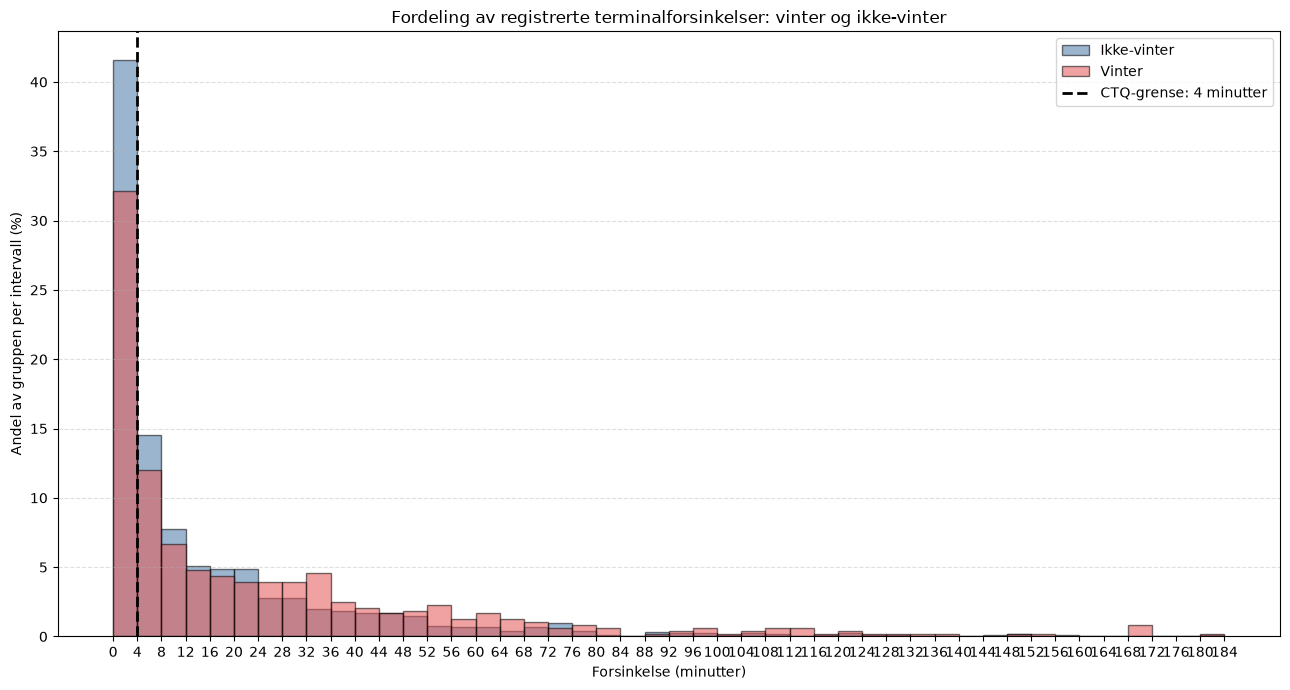

Felles 99-persentilgrense for figuren: 181.9 minutter
Forsinkelsesobservasjoner i figuren: 0–184 minutter
Utelatt fra Vinter-figuren: 0.62 %
Utelatt fra Ikke-vinter-figuren: 1.11 %


In [195]:
# Comparison of delay distributions

delay_col = "Forsinkelse - terminal"

# Convert delay values to numeric and exclude missing/negative delays
delay_vinter = pd.to_numeric(
    df_vinter[delay_col],
    errors="coerce"
)
delay_vinter = delay_vinter[
    delay_vinter >= 0
].dropna()

delay_ikke_vinter = pd.to_numeric(
    df_ikke_vinter[delay_col],
    errors="coerce"
)
delay_ikke_vinter = delay_ikke_vinter[
    delay_ikke_vinter >= 0
].dropna()

# Use one common 99th-percentile cutoff for both groups.
# This ensures that both distributions are displayed on the same scale.
combined_delay = pd.concat(
    [delay_vinter, delay_ikke_vinter]
)

p99_cutoff = combined_delay.quantile(0.99)

# Round the upper limit up to the nearest 4-minute interval
bin_width = 4
hist_max = int(
    (p99_cutoff + bin_width - 1) // bin_width
) * bin_width

bin_edges = range(
    0,
    hist_max + bin_width,
    bin_width
)

# Limit only the plotted distributions.
# The original delay series remain unchanged.
delay_vinter_plot = delay_vinter[
    delay_vinter <= hist_max
]

delay_ikke_vinter_plot = delay_ikke_vinter[
    delay_ikke_vinter <= hist_max
]

# Calculate the percentage excluded from each plotted distribution
excluded_vinter = (
    (len(delay_vinter) - len(delay_vinter_plot))
    / len(delay_vinter)
    * 100
)

excluded_ikke_vinter = (
    (len(delay_ikke_vinter) - len(delay_ikke_vinter_plot))
    / len(delay_ikke_vinter)
    * 100
)

# Plot normalized histograms
fig, ax = plt.subplots(figsize=(13, 7))

ax.hist(
    delay_ikke_vinter_plot,
    bins=bin_edges,
    weights=[
        100 / len(delay_ikke_vinter_plot)
    ] * len(delay_ikke_vinter_plot),
    alpha=0.55,
    color="#4C78A8",
    edgecolor="black",
    label="Ikke-vinter"
)

ax.hist(
    delay_vinter_plot,
    bins=bin_edges,
    weights=[
        100 / len(delay_vinter_plot)
    ] * len(delay_vinter_plot),
    alpha=0.55,
    color="#E45756",
    edgecolor="black",
    label="Vinter"
)

# CTQ threshold
ax.axvline(
    4,
    color="black",
    linestyle="--",
    linewidth=2,
    label="CTQ-grense: 4 minutter"
)

ax.set_title(
    "Fordeling av registrerte terminalforsinkelser: vinter og ikke-vinter"
)
ax.set_xlabel("Forsinkelse (minutter)")
ax.set_ylabel("Andel av gruppen per intervall (%)")

ax.set_xticks(list(bin_edges))
ax.grid(
    axis="y",
    linestyle="--",
    alpha=0.4
)

ax.legend()
plt.tight_layout()
plt.show()

print(
    f"Felles 99-persentilgrense for figuren: "
    f"{p99_cutoff:.1f} minutter"
)
print(
    f"Forsinkelsesobservasjoner i figuren: "
    f"0–{hist_max} minutter"
)
print(
    f"Utelatt fra Vinter-figuren: "
    f"{excluded_vinter:.2f} %"
)
print(
    f"Utelatt fra Ikke-vinter-figuren: "
    f"{excluded_ikke_vinter:.2f} %"
)

#### Pareto diagrams

##### Årsakskoder

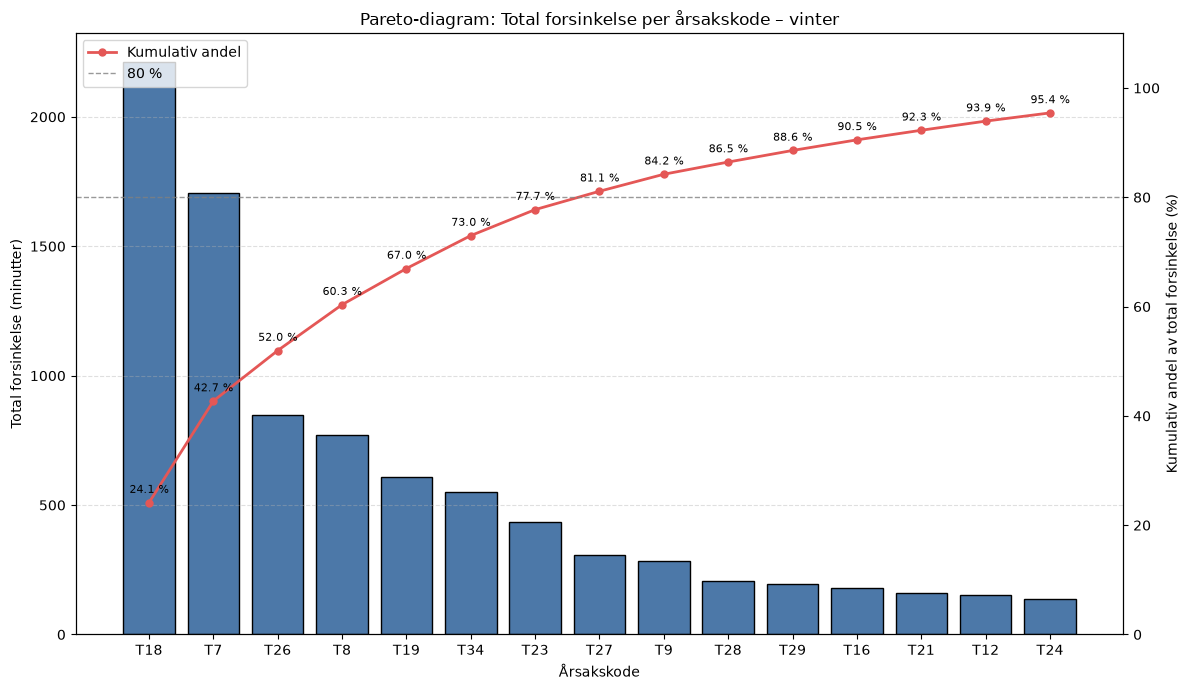


Pareto-diagram: Total forsinkelse per årsakskode – vinter
Total delay included: 9,167 minutes
Share covered by displayed top 15 codes: 95.44%


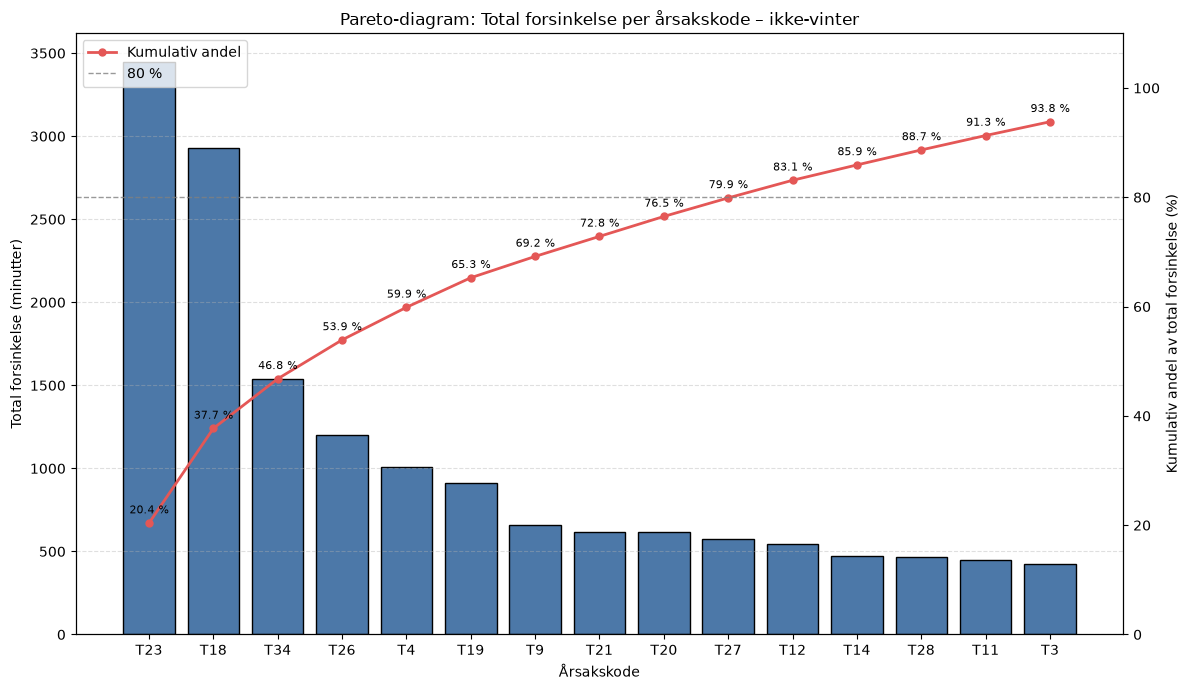


Pareto-diagram: Total forsinkelse per årsakskode – ikke-vinter
Total delay included: 16,911 minutes
Share covered by displayed top 15 codes: 93.82%


In [196]:
# Pareto diagrams for total delay by reason code

code_col = "Årsakskode - terminal (kode)"
delay_col = "Forsinkelse - terminal"
excluded_codes = {"T1", "T2"}


def prepare_reason_delay_data(data):
    """Calculate total non-negative delay per reason code."""

    working = data[[code_col, delay_col]].copy()

    working[delay_col] = pd.to_numeric(
        working[delay_col],
        errors="coerce"
    )

    working = working[
        working[code_col].notna()
        & working[delay_col].notna()
        & (working[delay_col] >= 0)
        & ~working[code_col].isin(excluded_codes)
    ].copy()

    reason_summary = (
        working
        .groupby(code_col)
        .agg(
            antall_registreringer=(code_col, "size"),
            total_forsinkelse=(delay_col, "sum")
        )
        .sort_values(
            "total_forsinkelse",
            ascending=False
        )
    )

    return reason_summary


# Prepare data for both comparison periods
vinter_reason_summary = prepare_reason_delay_data(df_vinter)
ikke_vinter_reason_summary = prepare_reason_delay_data(df_ikke_vinter)


def plot_delay_pareto(
    reason_summary,
    title,
    top_n=15
):
    """Plot a total-delay Pareto diagram."""

    # Display the most important codes
    plot_data = reason_summary.head(top_n).copy()

    total_delay = reason_summary["total_forsinkelse"].sum()

    if total_delay == 0 or plot_data.empty:
        print(f"No valid delay data available for: {title}")
        return

    # Calculate percentages relative to all included codes,
    # not only the displayed top codes
    plot_data["andel_prosent"] = (
        plot_data["total_forsinkelse"]
        / total_delay
        * 100
    )

    plot_data["kumulativ_andel_prosent"] = (
        plot_data["andel_prosent"].cumsum()
    )

    fig, ax1 = plt.subplots(figsize=(12, 7))

    x_positions = range(len(plot_data))

    ax1.bar(
        x_positions,
        plot_data["total_forsinkelse"],
        color="#4C78A8",
        edgecolor="black"
    )

    ax1.set_title(title)
    ax1.set_xlabel("Årsakskode")
    ax1.set_ylabel("Total forsinkelse (minutter)")
    ax1.set_xticks(list(x_positions))
    ax1.set_xticklabels(plot_data.index)
    ax1.grid(
        axis="y",
        linestyle="--",
        alpha=0.4
    )

    # Cumulative percentage line
    ax2 = ax1.twinx()

    ax2.plot(
        x_positions,
        plot_data["kumulativ_andel_prosent"],
        color="#E45756",
        marker="o",
        linewidth=2,
        markersize=5,
        label="Kumulativ andel"
    )

    ax2.set_ylabel(
        "Kumulativ andel av total forsinkelse (%)"
    )
    ax2.set_ylim(0, 110)

    ax2.axhline(
        80,
        color="gray",
        linestyle="--",
        linewidth=1,
        alpha=0.8,
        label="80 %"
    )

    # Add cumulative percentage labels
    for x, y in zip(
        x_positions,
        plot_data["kumulativ_andel_prosent"]
    ):
        ax2.annotate(
            f"{y:.1f} %",
            (x, y),
            xytext=(0, 7),
            textcoords="offset points",
            ha="center",
            fontsize=8
        )

    # Combine legends from both axes
    handles_1, labels_1 = ax1.get_legend_handles_labels()
    handles_2, labels_2 = ax2.get_legend_handles_labels()

    ax2.legend(
        handles_1 + handles_2,
        labels_1 + labels_2,
        loc="upper left"
    )

    plt.xticks(rotation=0)
    plt.tight_layout()
    plt.show()

    print(f"\n{title}")
    print(f"Total delay included: {total_delay:,.0f} minutes")
    print(
        f"Share covered by displayed top {len(plot_data)} codes: "
        f"{plot_data['kumulativ_andel_prosent'].iloc[-1]:.2f}%"
    )

    return plot_data


# Create the two seasonal Pareto diagrams
vinter_pareto = plot_delay_pareto(
    vinter_reason_summary,
    "Pareto-diagram: Total forsinkelse per årsakskode – vinter"
)

ikke_vinter_pareto = plot_delay_pareto(
    ikke_vinter_reason_summary,
    "Pareto-diagram: Total forsinkelse per årsakskode – ikke-vinter"
)

*Comment:* Let's check for the 99th percentile only, considering there were a few outliers accounting for a lot of delay minutes.

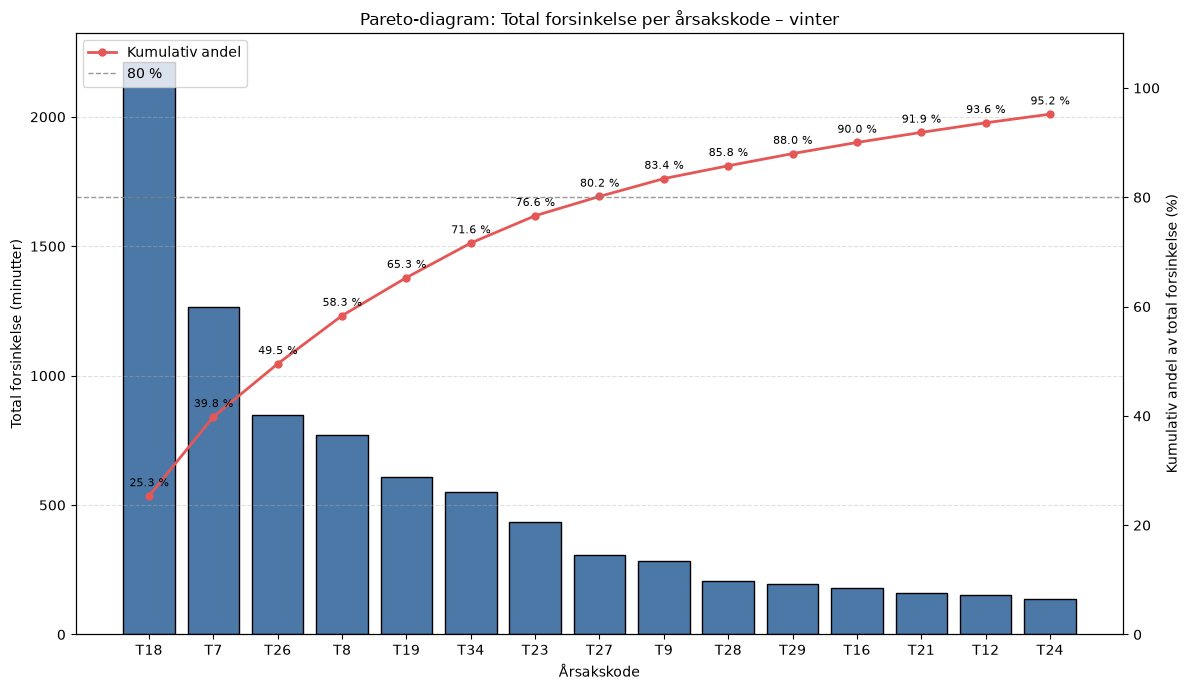


Pareto-diagram: Total forsinkelse per årsakskode – vinter
99-persentilgrense: 181.9 minutter
Total forsinkelse inkludert: 8,727 minutter
Andel dekket av viste topp 15 koder: 95.21%


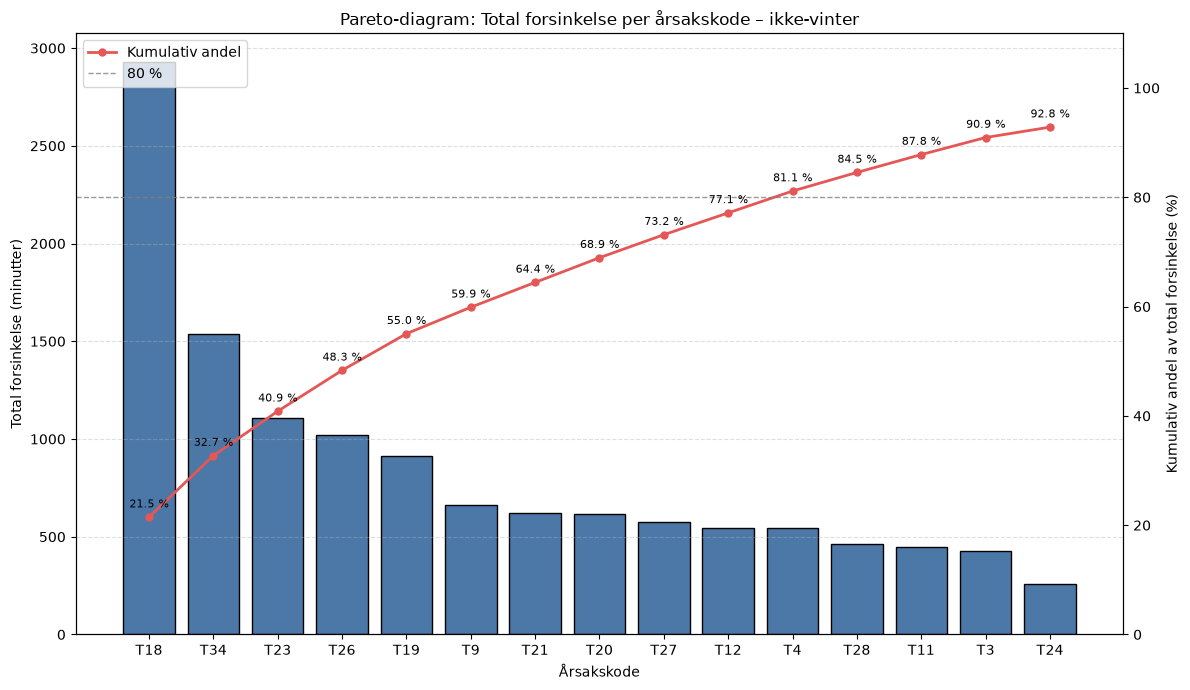


Pareto-diagram: Total forsinkelse per årsakskode – ikke-vinter
99-persentilgrense: 181.9 minutter
Total forsinkelse inkludert: 13,641 minutter
Andel dekket av viste topp 15 koder: 92.84%


In [197]:
# Pareto diagrams for total delay by reason code
# Delays above the common 99th percentile are excluded

code_col = "Årsakskode - terminal (kode)"
delay_col = "Forsinkelse - terminal"
excluded_codes = {"T1", "T2"}

# Uses p99_cutoff calculated in the histogram cell
pareto_cutoff = p99_cutoff


def prepare_reason_delay_data(data):
    """Calculate total non-negative delay per reason code below the 99th percentile."""

    working = data[[code_col, delay_col]].copy()

    working[delay_col] = pd.to_numeric(
        working[delay_col],
        errors="coerce"
    )

    working = working[
        working[code_col].notna()
        & working[delay_col].notna()
        & (working[delay_col] >= 0)
        & (working[delay_col] <= pareto_cutoff)
        & ~working[code_col].isin(excluded_codes)
    ].copy()

    reason_summary = (
        working
        .groupby(code_col)
        .agg(
            antall_registreringer=(code_col, "size"),
            total_forsinkelse=(delay_col, "sum")
        )
        .sort_values(
            "total_forsinkelse",
            ascending=False
        )
    )

    return reason_summary


# Prepare data for both comparison periods
vinter_reason_summary = prepare_reason_delay_data(df_vinter)
ikke_vinter_reason_summary = prepare_reason_delay_data(df_ikke_vinter)


def plot_delay_pareto(
    reason_summary,
    title,
    top_n=15
):
    """Plot a total-delay Pareto diagram."""

    plot_data = reason_summary.head(top_n).copy()
    total_delay = reason_summary["total_forsinkelse"].sum()

    if total_delay == 0 or plot_data.empty:
        print(f"Ingen gyldige forsinkelsesdata: {title}")
        return

    # Percentages are relative to all included reason codes
    plot_data["andel_prosent"] = (
        plot_data["total_forsinkelse"]
        / total_delay
        * 100
    )

    plot_data["kumulativ_andel_prosent"] = (
        plot_data["andel_prosent"].cumsum()
    )

    fig, ax1 = plt.subplots(figsize=(12, 7))

    x_positions = range(len(plot_data))

    ax1.bar(
        x_positions,
        plot_data["total_forsinkelse"],
        color="#4C78A8",
        edgecolor="black"
    )

    ax1.set_title(title)
    ax1.set_xlabel("Årsakskode")
    ax1.set_ylabel("Total forsinkelse (minutter)")
    ax1.set_xticks(list(x_positions))
    ax1.set_xticklabels(plot_data.index)
    ax1.grid(
        axis="y",
        linestyle="--",
        alpha=0.4
    )

    ax2 = ax1.twinx()

    ax2.plot(
        x_positions,
        plot_data["kumulativ_andel_prosent"],
        color="#E45756",
        marker="o",
        linewidth=2,
        markersize=5,
        label="Kumulativ andel"
    )

    ax2.set_ylabel(
        "Kumulativ andel av total forsinkelse (%)"
    )
    ax2.set_ylim(0, 110)

    ax2.axhline(
        80,
        color="gray",
        linestyle="--",
        linewidth=1,
        alpha=0.8,
        label="80 %"
    )

    for x, y in zip(
        x_positions,
        plot_data["kumulativ_andel_prosent"]
    ):
        ax2.annotate(
            f"{y:.1f} %",
            (x, y),
            xytext=(0, 7),
            textcoords="offset points",
            ha="center",
            fontsize=8
        )

    handles_1, labels_1 = ax1.get_legend_handles_labels()
    handles_2, labels_2 = ax2.get_legend_handles_labels()

    ax2.legend(
        handles_1 + handles_2,
        labels_1 + labels_2,
        loc="upper left"
    )

    plt.tight_layout()
    plt.show()

    print(f"\n{title}")
    print(
        f"99-persentilgrense: {pareto_cutoff:.1f} minutter"
    )
    print(
        f"Total forsinkelse inkludert: "
        f"{total_delay:,.0f} minutter"
    )
    print(
        f"Andel dekket av viste topp {len(plot_data)} koder: "
        f"{plot_data['kumulativ_andel_prosent'].iloc[-1]:.2f}%"
    )

    return plot_data


# Create the two seasonal Pareto diagrams
vinter_pareto = plot_delay_pareto(
    vinter_reason_summary,
    "Pareto-diagram: Total forsinkelse per årsakskode – vinter"
)

ikke_vinter_pareto = plot_delay_pareto(
    ikke_vinter_reason_summary,
    "Pareto-diagram: Total forsinkelse per årsakskode – ikke-vinter"
)

*Comment:* These results are more reliable for the "ordinary" operations when outliers are excluded. For the winter season, the order and magnitude of the reasons accounting for 80% of delay minutes are the same with/without outliers. For the "summer" season however, the order changes more, with the top 3 swapping positions, as well some more codes changing positions within top 15.

##### Tognummer

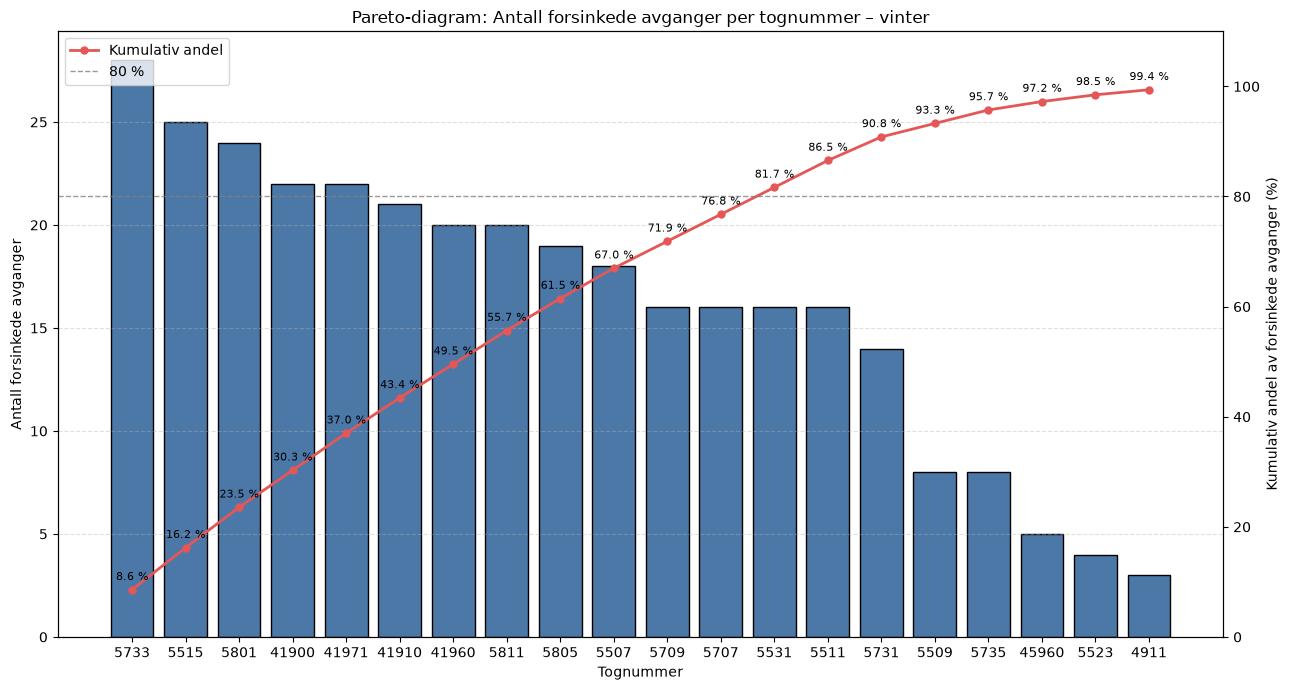


Pareto-diagram: Antall forsinkede avganger per tognummer – vinter
99-persentilgrense: 181.9 minutter
Totalt antall forsinkede avganger inkludert: 327
Andel dekket av viste topp 20 tognumre: 99.39%


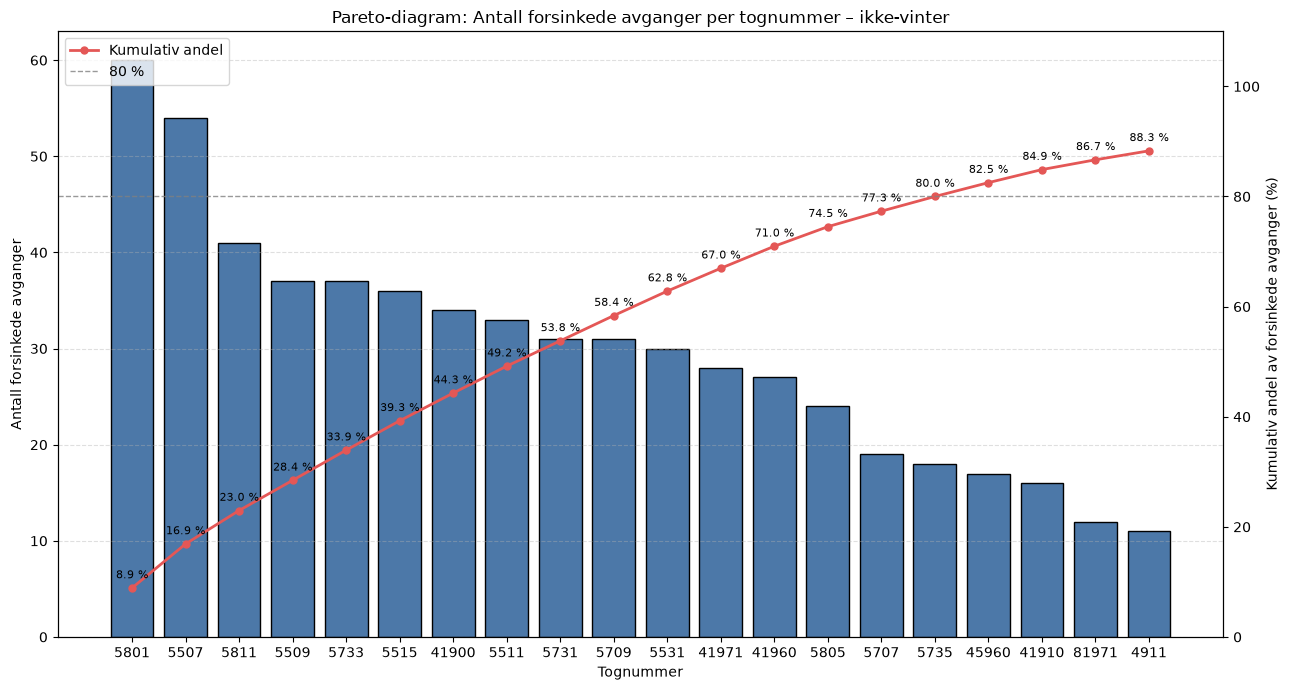


Pareto-diagram: Antall forsinkede avganger per tognummer – ikke-vinter
99-persentilgrense: 181.9 minutter
Totalt antall forsinkede avganger inkludert: 675
Andel dekket av viste topp 20 tognumre: 88.30%


In [198]:
# Pareto diagrams for number of delayed departures by train number

train_col = "Tognummer"
delay_col = "Forsinkelse - terminal"

# Use the common 99th-percentile cutoff from the histogram
pareto_cutoff = p99_cutoff

# Use > 0 because a zero-minute delay is not a delayed departure.
# Change this to 4 if the Pareto should show departures exceeding the CTQ.
delay_threshold = 4


def prepare_train_frequency_data(data):
    """Count delayed departures per train number."""

    working = data[[train_col, delay_col]].copy()

    working[delay_col] = pd.to_numeric(
        working[delay_col],
        errors="coerce"
    )

    working = working[
        working[train_col].notna()
        & working[delay_col].notna()
        & (working[delay_col] >= delay_threshold)
        & (working[delay_col] <= pareto_cutoff)
    ].copy()

    train_summary = (
        working
        .groupby(train_col)
        .size()
        .to_frame("antall_forsinkede_avganger")
        .sort_values(
            "antall_forsinkede_avganger",
            ascending=False
        )
    )

    return train_summary


# Prepare both seasonal groups
vinter_train_frequency = prepare_train_frequency_data(df_vinter)
ikke_vinter_train_frequency = prepare_train_frequency_data(
    df_ikke_vinter
)


def plot_train_frequency_pareto(
    train_summary,
    title,
    top_n=20
):
    """Plot a Pareto diagram by number of delayed departures."""

    plot_data = train_summary.head(top_n).copy()
    total_delayed_departures = train_summary[
        "antall_forsinkede_avganger"
    ].sum()

    if total_delayed_departures == 0 or plot_data.empty:
        print(f"Ingen gyldige data: {title}")
        return

    # Percentage relative to all included delayed departures
    plot_data["andel_prosent"] = (
        plot_data["antall_forsinkede_avganger"]
        / total_delayed_departures
        * 100
    )

    plot_data["kumulativ_andel_prosent"] = (
        plot_data["andel_prosent"].cumsum()
    )

    fig, ax1 = plt.subplots(figsize=(13, 7))

    x_positions = range(len(plot_data))

    ax1.bar(
        x_positions,
        plot_data["antall_forsinkede_avganger"],
        color="#4C78A8",
        edgecolor="black"
    )

    ax1.set_title(title)
    ax1.set_xlabel("Tognummer")
    ax1.set_ylabel("Antall forsinkede avganger")
    ax1.set_xticks(list(x_positions))
    ax1.set_xticklabels(plot_data.index.astype(str))
    ax1.grid(
        axis="y",
        linestyle="--",
        alpha=0.4
    )

    # Cumulative percentage line
    ax2 = ax1.twinx()

    ax2.plot(
        x_positions,
        plot_data["kumulativ_andel_prosent"],
        color="#E45756",
        marker="o",
        linewidth=2,
        markersize=5,
        label="Kumulativ andel"
    )

    ax2.set_ylabel(
        "Kumulativ andel av forsinkede avganger (%)"
    )
    ax2.set_ylim(0, 110)

    ax2.axhline(
        80,
        color="gray",
        linestyle="--",
        linewidth=1,
        alpha=0.8,
        label="80 %"
    )

    for x, y in zip(
        x_positions,
        plot_data["kumulativ_andel_prosent"]
    ):
        ax2.annotate(
            f"{y:.1f} %",
            (x, y),
            xytext=(0, 7),
            textcoords="offset points",
            ha="center",
            fontsize=8
        )

    ax2.legend(
        loc="upper left"
    )

    plt.tight_layout()
    plt.show()

    print(f"\n{title}")
    print(
        f"99-persentilgrense: "
        f"{pareto_cutoff:.1f} minutter"
    )
    print(
        f"Totalt antall forsinkede avganger inkludert: "
        f"{total_delayed_departures}"
    )
    print(
        f"Andel dekket av viste topp {len(plot_data)} tognumre: "
        f"{plot_data['kumulativ_andel_prosent'].iloc[-1]:.2f}%"
    )

    return plot_data


# Create the two seasonal frequency Pareto diagrams
vinter_train_frequency_pareto = plot_train_frequency_pareto(
    vinter_train_frequency,
    "Pareto-diagram: Antall forsinkede avganger per tognummer – vinter"
)

ikke_vinter_train_frequency_pareto = plot_train_frequency_pareto(
    ikke_vinter_train_frequency,
    "Pareto-diagram: Antall forsinkede avganger per tognummer – ikke-vinter"
)

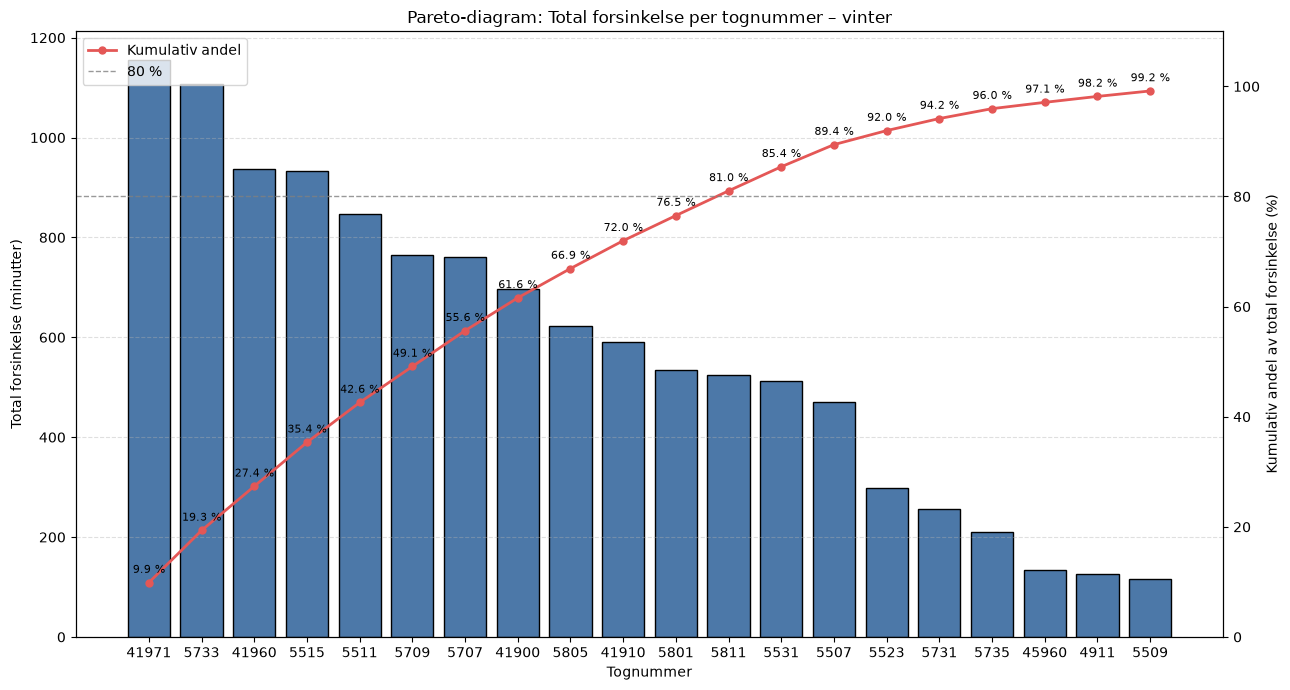


Pareto-diagram: Total forsinkelse per tognummer – vinter
99-persentilgrense: 181.9 minutter
Total forsinkelse inkludert: 11,694 minutter
Andel dekket av viste topp 20 tognumre: 99.17%


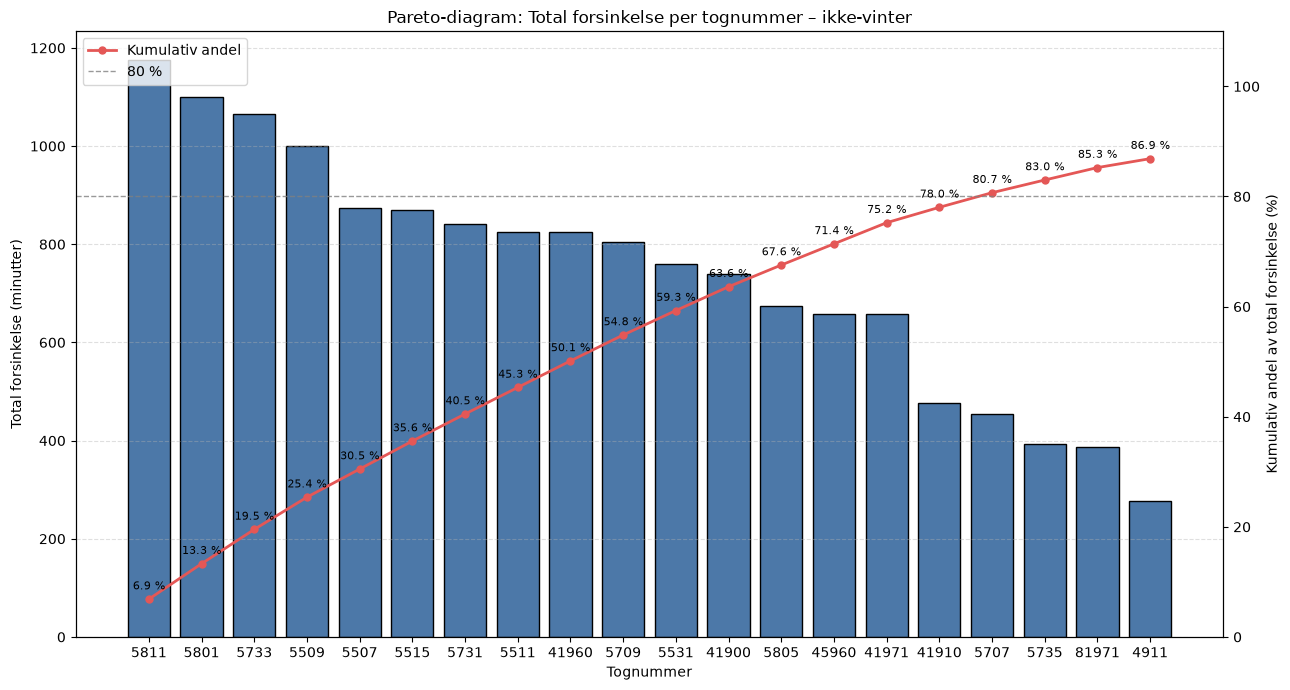


Pareto-diagram: Total forsinkelse per tognummer – ikke-vinter
99-persentilgrense: 181.9 minutter
Total forsinkelse inkludert: 17,095 minutter
Andel dekket av viste topp 20 tognumre: 86.87%


In [199]:
# Pareto diagrams for total delay by train number

train_col = "Tognummer"
delay_col = "Forsinkelse - terminal"

# Uses the common p99_cutoff from the histogram cell
pareto_cutoff = p99_cutoff


# Use > 0 because a zero-minute delay is not a delayed departure.
# Change this to 4 if the Pareto should show departures exceeding the CTQ.
delay_threshold = 4

def prepare_train_delay_data(data):
    """Calculate total non-negative delay per train number."""

    working = data[[train_col, delay_col]].copy()

    working[delay_col] = pd.to_numeric(
        working[delay_col],
        errors="coerce"
    )

    working = working[
        working[train_col].notna()
        & working[delay_col].notna()
        & (working[delay_col] >= delay_threshold)
        & (working[delay_col] <= pareto_cutoff)
    ].copy()

    train_summary = (
        working
        .groupby(train_col)
        .agg(
            antall_registreringer=(train_col, "size"),
            total_forsinkelse=(delay_col, "sum")
        )
        .sort_values(
            "total_forsinkelse",
            ascending=False
        )
    )

    return train_summary


# Prepare both seasonal groups
vinter_train_summary = prepare_train_delay_data(df_vinter)
ikke_vinter_train_summary = prepare_train_delay_data(df_ikke_vinter)


def plot_train_pareto(
    train_summary,
    title,
    top_n=20
):
    """Plot a total-delay Pareto diagram by train number."""

    plot_data = train_summary.head(top_n).copy()
    total_delay = train_summary["total_forsinkelse"].sum()

    if total_delay == 0 or plot_data.empty:
        print(f"Ingen gyldige forsinkelsesdata: {title}")
        return

    # Percentage relative to all included train numbers
    plot_data["andel_prosent"] = (
        plot_data["total_forsinkelse"]
        / total_delay
        * 100
    )

    plot_data["kumulativ_andel_prosent"] = (
        plot_data["andel_prosent"].cumsum()
    )

    fig, ax1 = plt.subplots(figsize=(13, 7))

    x_positions = range(len(plot_data))

    ax1.bar(
        x_positions,
        plot_data["total_forsinkelse"],
        color="#4C78A8",
        edgecolor="black"
    )

    ax1.set_title(title)
    ax1.set_xlabel("Tognummer")
    ax1.set_ylabel("Total forsinkelse (minutter)")
    ax1.set_xticks(list(x_positions))
    ax1.set_xticklabels(plot_data.index.astype(str))
    ax1.grid(
        axis="y",
        linestyle="--",
        alpha=0.4
    )

    ax2 = ax1.twinx()

    ax2.plot(
        x_positions,
        plot_data["kumulativ_andel_prosent"],
        color="#E45756",
        marker="o",
        linewidth=2,
        markersize=5,
        label="Kumulativ andel"
    )

    ax2.set_ylabel(
        "Kumulativ andel av total forsinkelse (%)"
    )
    ax2.set_ylim(0, 110)

    ax2.axhline(
        80,
        color="gray",
        linestyle="--",
        linewidth=1,
        alpha=0.8,
        label="80 %"
    )

    for x, y in zip(
        x_positions,
        plot_data["kumulativ_andel_prosent"]
    ):
        ax2.annotate(
            f"{y:.1f} %",
            (x, y),
            xytext=(0, 7),
            textcoords="offset points",
            ha="center",
            fontsize=8
        )

    handles_1, labels_1 = ax1.get_legend_handles_labels()
    handles_2, labels_2 = ax2.get_legend_handles_labels()

    ax2.legend(
        handles_1 + handles_2,
        labels_1 + labels_2,
        loc="upper left"
    )

    plt.tight_layout()
    plt.show()

    print(f"\n{title}")
    print(f"99-persentilgrense: {pareto_cutoff:.1f} minutter")
    print(f"Total forsinkelse inkludert: {total_delay:,.0f} minutter")
    print(
        f"Andel dekket av viste topp {len(plot_data)} tognumre: "
        f"{plot_data['kumulativ_andel_prosent'].iloc[-1]:.2f}%"
    )

    return plot_data


# Create the two seasonal Pareto diagrams
vinter_train_pareto = plot_train_pareto(
    vinter_train_summary,
    "Pareto-diagram: Total forsinkelse per tognummer – vinter"
)

ikke_vinter_train_pareto = plot_train_pareto(
    ikke_vinter_train_summary,
    "Pareto-diagram: Total forsinkelse per tognummer – ikke-vinter"
)

In [200]:
print("Winter delays:")
display(vinter_train_frequency_pareto)
print("Summer delays:")
display(ikke_vinter_train_frequency_pareto)

Winter delays:


,antall_forsinkede_avganger,andel_prosent,kumulativ_andel_prosent
Tognummer,,,
5733,28,8.562691,8.562691
5515,25,7.645260,16.207951
5801,24,7.339450,23.547401
41900,22,6.727829,30.275229
41971,22,6.727829,37.003058
41910,21,6.422018,43.425076
41960,20,6.116208,49.541284
5811,20,6.116208,55.657492
5805,19,5.810398,61.467890


Summer delays:


,antall_forsinkede_avganger,andel_prosent,kumulativ_andel_prosent
Tognummer,,,
5801,60,8.888889,8.888889
5507,54,8.000000,16.888889
5811,41,6.074074,22.962963
5509,37,5.481481,28.444444
5733,37,5.481481,33.925926
5515,36,5.333333,39.259259
41900,34,5.037037,44.296296
5511,33,4.888889,49.185185
5731,31,4.592593,53.777778


*Comment:* Compared to the årsakskode-diagrams, the cumulative percentage of delays are more linear per `Tognummer`, but yet there are differences between the trains. Based on the number of departures (instead of delay minutes), there are 12-13 trains during winter which account for about 80% of the delays, while during the summer season there are 16 trains. 

Nevertheless, there are some `Tognummer` which appear freuqeuntly in both summer/winter-delays: 5801, 5733, 5515 and 5507.

However, this is number of delays, let's compare actual delay rates compared to all departures.

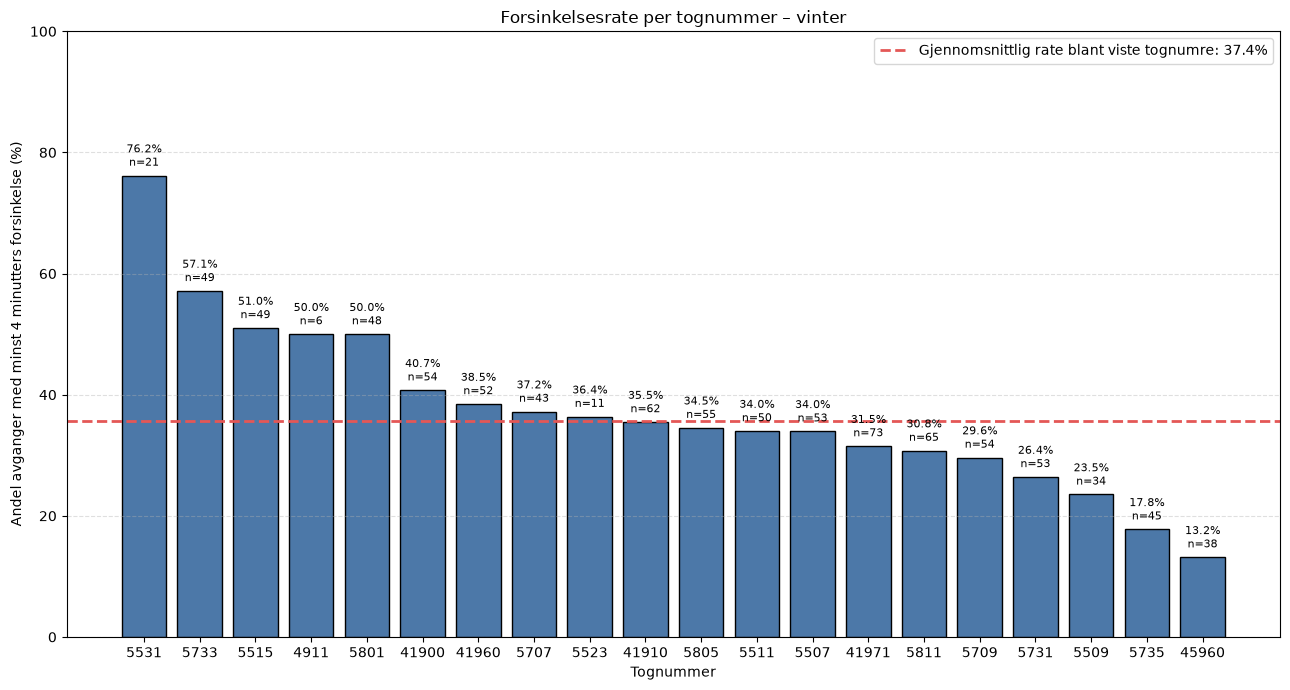


Forsinkelsesrate per tognummer – vinter
Minimum antall avganger per tognummer: 5


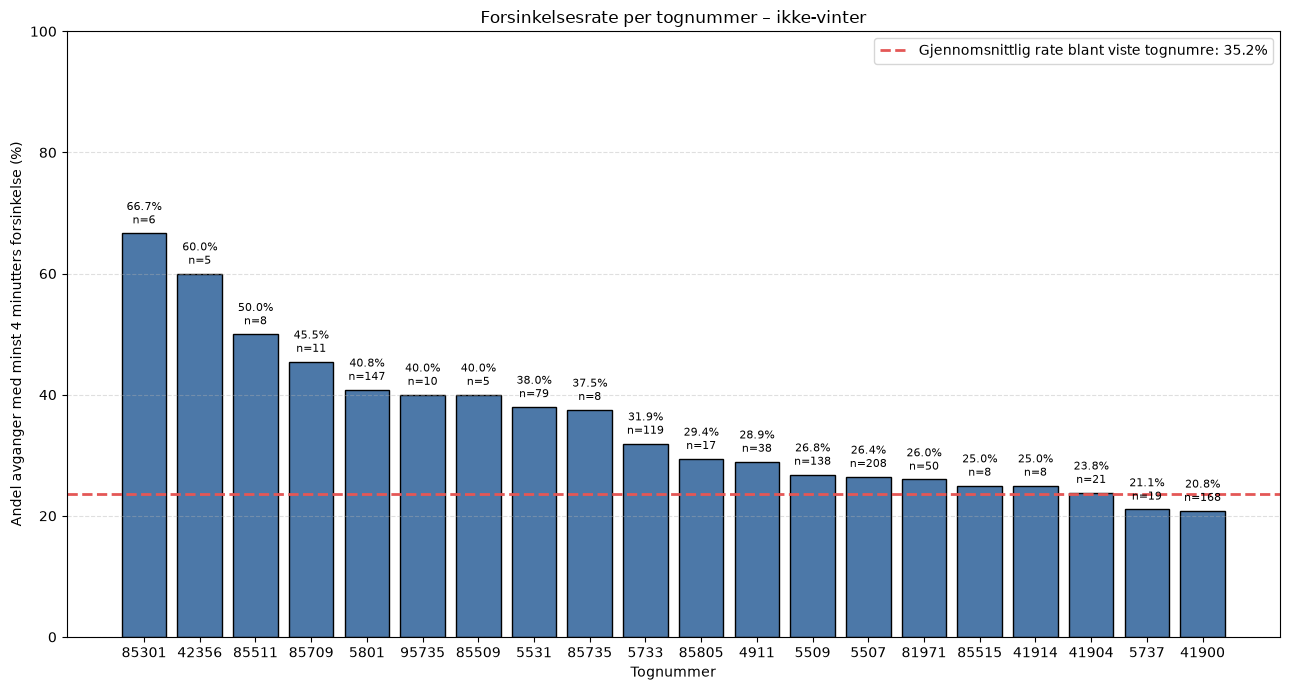


Forsinkelsesrate per tognummer – ikke-vinter
Minimum antall avganger per tognummer: 5


In [201]:
# Delay rate by train number
# CTQ: at least 4 minutes

train_col = "Tognummer"
delay_col = "Forsinkelse - terminal"

delay_threshold = 4
minimum_departures = 5


def prepare_train_delay_rate_data(data):
    """Calculate the CTQ delay rate for each train number."""

    working = data[[train_col, delay_col]].copy()

    working[delay_col] = pd.to_numeric(
        working[delay_col],
        errors="coerce"
    )

    # Keep rows with a valid terminal-delay value.
    # Negative delays remain in the denominator.
    working = working[
        working[train_col].notna()
        & working[delay_col].notna()
    ].copy()

    train_summary = (
        working
        .groupby(train_col)
        .agg(
            antall_avganger=(train_col, "size"),
            antall_avganger_minst_4_min=(
                delay_col,
                lambda values: (values >= delay_threshold).sum()
            )
        )
    )

    # Calculate delay rate
    train_summary["forsinkelsesrate_prosent"] = (
        train_summary["antall_avganger_minst_4_min"]
        / train_summary["antall_avganger"]
        * 100
    )

    # Exclude train numbers with too few observations
    train_summary = train_summary[
        train_summary["antall_avganger"] >= minimum_departures
    ].copy()

    return train_summary.sort_values(
        "forsinkelsesrate_prosent",
        ascending=False
    )


# Prepare both seasonal groups
vinter_train_delay_rate = prepare_train_delay_rate_data(
    df_vinter
)

ikke_vinter_train_delay_rate = prepare_train_delay_rate_data(
    df_ikke_vinter
)


def plot_train_delay_rate(
    train_summary,
    title,
    top_n=20
):
    """Plot train numbers ranked by CTQ delay rate."""

    plot_data = train_summary.head(top_n).copy()

    if plot_data.empty:
        print(f"Ingen gyldige data: {title}")
        return

    fig, ax = plt.subplots(figsize=(13, 7))

    x_positions = range(len(plot_data))

    bars = ax.bar(
        x_positions,
        plot_data["forsinkelsesrate_prosent"],
        color="#4C78A8",
        edgecolor="black"
    )

    ax.axhline(
        train_summary["forsinkelsesrate_prosent"].mean(),
        color="#E45756",
        linestyle="--",
        linewidth=2,
        label=(
            "Gjennomsnittlig rate blant viste tognumre: "
            f"{plot_data['forsinkelsesrate_prosent'].mean():.1f}%"
        )
    )

    ax.set_title(title)
    ax.set_xlabel("Tognummer")
    ax.set_ylabel(
        "Andel avganger med minst 4 minutters forsinkelse (%)"
    )
    ax.set_xticks(list(x_positions))
    ax.set_xticklabels(plot_data.index.astype(str))
    ax.set_ylim(0, 100)
    ax.grid(
        axis="y",
        linestyle="--",
        alpha=0.4
    )

    # Add rate and denominator labels
    for bar, (_, row) in zip(bars, plot_data.iterrows()):
        ax.text(
            bar.get_x() + bar.get_width() / 2,
            bar.get_height() + 1,
            (
                f"{row['forsinkelsesrate_prosent']:.1f}%\n"
                f"n={row['antall_avganger']}"
            ),
            ha="center",
            va="bottom",
            fontsize=8
        )

    ax.legend(loc="upper right")
    plt.tight_layout()
    plt.show()

    print(f"\n{title}")
    print(
        f"Minimum antall avganger per tognummer: "
        f"{minimum_departures}"
    )

    return plot_data


# Plot the seasonal delay-rate comparisons
vinter_train_delay_rate_plot = plot_train_delay_rate(
    vinter_train_delay_rate,
    "Forsinkelsesrate per tognummer – vinter"
)

ikke_vinter_train_delay_rate_plot = plot_train_delay_rate(
    ikke_vinter_train_delay_rate,
    "Forsinkelsesrate per tognummer – ikke-vinter"
)

##### Combining Tognummer & Årsakskoder
Let's look closer at the top 3 trains with the highest delay rate during the summer and winter season, and look at which delay codes account for most of these delay minutes.

Pareto diagram of total terminal-delay minutes by reason code among the three train numbers with the highest CTQ delay rate:


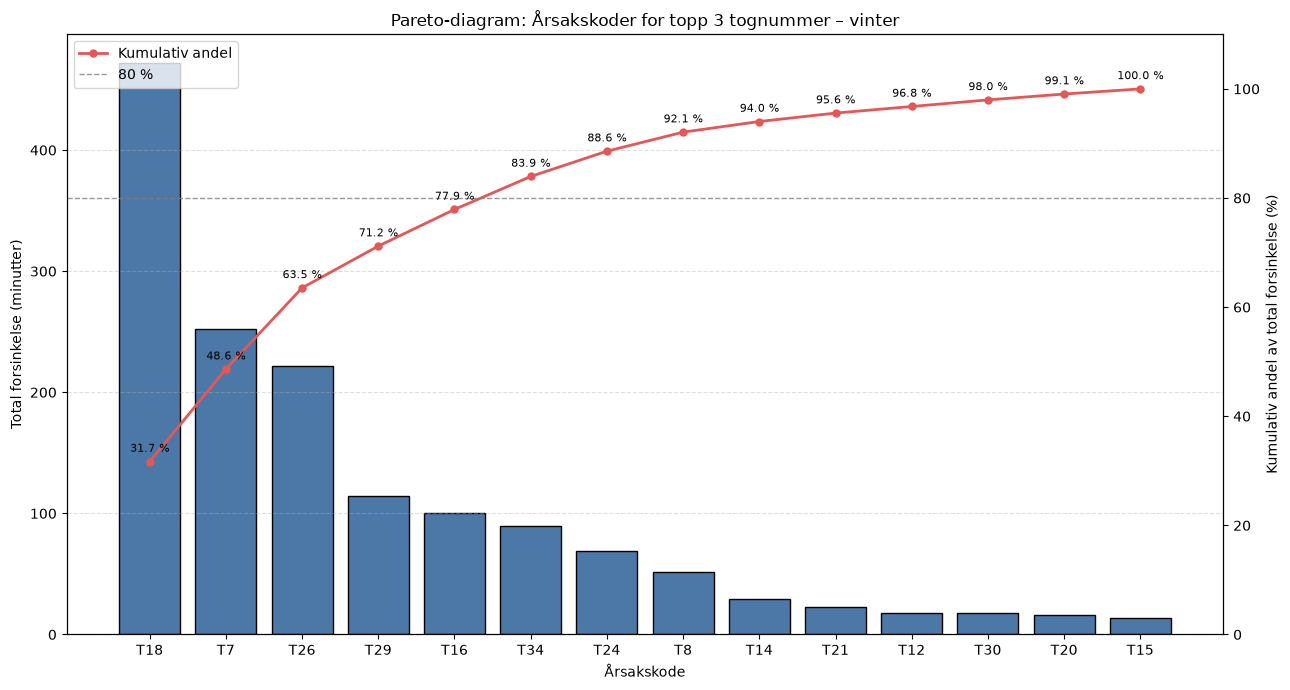

Pareto-diagram: Årsakskoder for topp 3 tognummer – vinter
Tognummer inkludert: 5531, 5733, 5515
99-persentilgrense: 181.9 minutter
Total forsinkelse inkludert: 1,489 minutter
Top 14 koder dekker: 100.00%


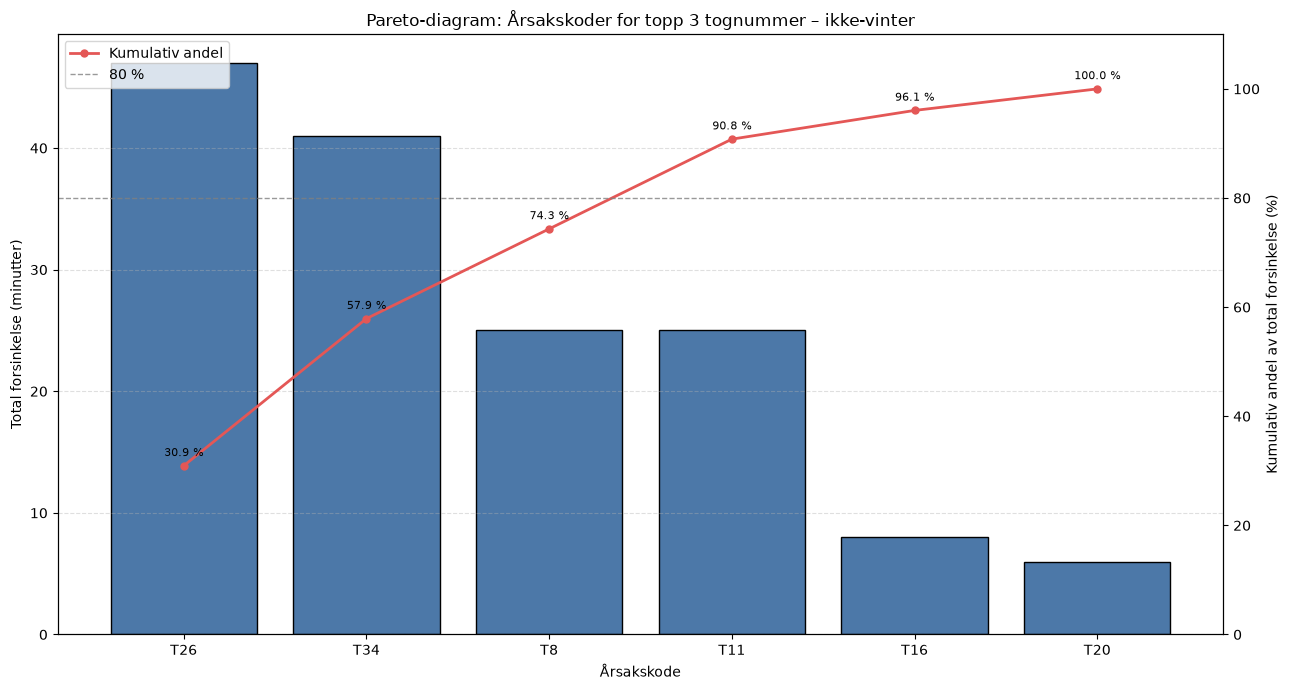

Pareto-diagram: Årsakskoder for topp 3 tognummer – ikke-vinter
Tognummer inkludert: 85301, 42356, 85511
99-persentilgrense: 181.9 minutter
Total forsinkelse inkludert: 152 minutter
Top 6 koder dekker: 100.00%


In [202]:
# Pareto diagrams of reason codes for the top 3 trains by delay rate

code_col = "Årsakskode - terminal (kode)"
delay_col = "Forsinkelse - terminal"
excluded_codes = {"T1", "T2"}


def prepare_top_train_reason_pareto(
    data,
    top_trains
):
    """Aggregate total delay by reason code for selected trains."""

    selected_trains = top_trains.index

    working = data[
        data["Tognummer"].isin(selected_trains)
    ][
        ["Tognummer", code_col, delay_col]
    ].copy()

    working[delay_col] = pd.to_numeric(
        working[delay_col],
        errors="coerce"
    )

    working = working[
        working[code_col].notna()
        & ~working[code_col].isin(excluded_codes)
        & working[delay_col].notna()
        & (working[delay_col] >= 0)
        & (working[delay_col] <= pareto_cutoff)
    ].copy()

    summary = (
        working
        .groupby(code_col)
        .agg(
            antall_registreringer=(code_col, "size"),
            total_forsinkelse=(delay_col, "sum")
        )
        .sort_values(
            "total_forsinkelse",
            ascending=False
        )
    )

    return summary


def plot_top_train_reason_pareto(
    reason_summary,
    top_trains,
    title,
    top_n=15
):
    """Plot a total-delay Pareto diagram for selected trains."""

    plot_data = reason_summary.head(top_n).copy()
    total_delay = reason_summary["total_forsinkelse"].sum()

    if plot_data.empty or total_delay == 0:
        print(f"Ingen gyldige data: {title}")
        return

    plot_data["andel_prosent"] = (
        plot_data["total_forsinkelse"]
        / total_delay
        * 100
    )

    plot_data["kumulativ_andel_prosent"] = (
        plot_data["andel_prosent"].cumsum()
    )

    fig, ax1 = plt.subplots(figsize=(13, 7))

    x_positions = range(len(plot_data))

    ax1.bar(
        x_positions,
        plot_data["total_forsinkelse"],
        color="#4C78A8",
        edgecolor="black"
    )

    ax1.set_title(title)
    ax1.set_xlabel("Årsakskode")
    ax1.set_ylabel("Total forsinkelse (minutter)")
    ax1.set_xticks(list(x_positions))
    ax1.set_xticklabels(plot_data.index)
    ax1.grid(
        axis="y",
        linestyle="--",
        alpha=0.4
    )

    ax2 = ax1.twinx()

    ax2.plot(
        x_positions,
        plot_data["kumulativ_andel_prosent"],
        color="#E45756",
        marker="o",
        linewidth=2,
        markersize=5,
        label="Kumulativ andel"
    )

    ax2.set_ylabel(
        "Kumulativ andel av total forsinkelse (%)"
    )
    ax2.set_ylim(0, 110)

    ax2.axhline(
        80,
        color="gray",
        linestyle="--",
        linewidth=1,
        alpha=0.8,
        label="80 %"
    )

    for x, y in zip(
        x_positions,
        plot_data["kumulativ_andel_prosent"]
    ):
        ax2.annotate(
            f"{y:.1f} %",
            (x, y),
            xytext=(0, 7),
            textcoords="offset points",
            ha="center",
            fontsize=8
        )

    ax2.legend(loc="upper left")

    plt.tight_layout()
    plt.show()

    print(
        f"{title}\n"
        f"Tognummer inkludert: "
        f"{', '.join(top_trains.index.astype(str))}\n"
        f"99-persentilgrense: {pareto_cutoff:.1f} minutter\n"
        f"Total forsinkelse inkludert: {total_delay:,.0f} minutter\n"
        f"Top {len(plot_data)} koder dekker: "
        f"{plot_data['kumulativ_andel_prosent'].iloc[-1]:.2f}%"
    )

    return plot_data


# Prepare reason-code summaries for the top three trains
vinter_top3_reason_summary = prepare_top_train_reason_pareto(
    df_vinter,
    vinter_top3
)

ikke_vinter_top3_reason_summary = prepare_top_train_reason_pareto(
    df_ikke_vinter,
    ikke_vinter_top3
)

print("Pareto diagram of total terminal-delay minutes by reason code among the three train numbers with the highest CTQ delay rate:")

# Create the two Pareto diagrams
vinter_top3_reason_pareto = plot_top_train_reason_pareto(
    vinter_top3_reason_summary,
    vinter_top3,
    "Pareto-diagram: Årsakskoder for topp 3 tognummer – vinter"
)

ikke_vinter_top3_reason_pareto = plot_top_train_reason_pareto(
    ikke_vinter_top3_reason_summary,
    ikke_vinter_top3,
    "Pareto-diagram: Årsakskoder for topp 3 tognummer – ikke-vinter"
)

*Comment:* The top codes causing delays for the top 3 highest delay-rate tognummer, are a bit different than the general findings. This suggests that the delay problem is not driven by **one** universal cause across all train services. However, frequent caudes are T18, T26, T34 and T7 (7 is winter only).

In addition, the code "T34 - annen feil" appears a lot in all pareto-diagrams, regardless of filtering. This suggests that the terminal codes might not capture all possible reason-categories.

#### Process times comparisons